# Tarea de Ejecución 03: Aplicación y Evaluación Empírica de Modelos CART y Ensamblados

En forma individual o en pares realice lo siguiente:

1. **[Pregunta 1](#pregunta-1).** Entrene modelos de árboles de decisión con criterios de impureza diferentes (índice gini y entropía) usando el dataset “breast_cancer” de scikit-learn, compare su eficiencia con respecto a un modelo lineal como el Regresor Logístico. ¿Cuál es mejor?
2. **[Pregunta 2](#pregunta-2).** Entrene modelos de árboles de decisión con varias configuraciones de hiper parámetros usando el dataset auto_mpg, comparar su eficiencia con respecto a un modelo lineal como el Regresor Lineal. ¿Cuál es el mejor?
3. **[Pregunta 3](#pregunta-3).** Entrene un modelo ensemble clasificador, y compare su eficiencia con respecto a un modelo individual. ¿Cuál es mejor?
4. **[Pregunta 4](#pregunta-4).** Entrene un modelo bagging regresor o clasificador y compare su eficiencia con respecto a un modelo individual. ¿Cuál es el mejor?
5. **[Pregunta 5](#pregunta-5).** Entrene un modelo RandomForest y compare su eficiencia con respecto a un modelo XGBoost. ¿Cuál es mejor?

El cuaderno sigue ese orden: datos y protocolo, preguntas 1 a 5, conclusiones y una comprobación de dos modelos. Cada pregunta cita la indicación, muestra las métricas ya calculadas y cierra con la respuesta. Las respuestas están en `README.md`. El diseño experimental está en `diseño_experimental.md`. El entrenamiento de cada pregunta está en `src/pregunta_1.py` a `src/pregunta_5.py`.


In [1]:
import json
import math
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src'))
results = json.loads((ROOT / 'results_metrics.json').read_text(encoding='utf-8'))
print('Semilla:', results['meta']['seed'])
print('Python:', results['meta']['python'])
print('Inicio del experimento:', results['meta']['started_at'])
print('Pregunta 1. Gini, entropía y regresión logística:', results['item1']['conclusion']['winner'])
print('Pregunta 2. Árboles de regresión y regresión lineal:', results['item2']['conclusion']['winner'])
print('Pregunta 3. Ensamble clasificador y modelo individual:', results['item3']['conclusion']['winner'])
print('Pregunta 4. Bagging clasificador:', results['item4']['classification']['best_bagging'])
print('Pregunta 4. Bagging regresor:', results['item4']['regression']['best_bagging'])
print('Pregunta 5. Random Forest y XGBoost, clasificación:', results['item5']['classification']['conclusion']['winner'])
print('Pregunta 5. Random Forest y XGBoost, regresión:', results['item5']['regression']['conclusion']['winner'])


Semilla: 42
Python: 3.12.10
Inicio del experimento: 2026-10-20 15:59:47
Pregunta 1. Gini, entropía y regresión logística: Regresión logística
Pregunta 2. Árboles de regresión y regresión lineal: Árbol error absoluto
Pregunta 3. Ensamble clasificador y modelo individual: Regresión logística
Pregunta 4. Bagging clasificador: Bagging (200)
Pregunta 4. Bagging regresor: Bagging (200)
Pregunta 5. Random Forest y XGBoost, clasificación: Random Forest base
Pregunta 5. Random Forest y XGBoost, regresión: Random Forest optimizado


## Datos y protocolo experimental

### Arquitectura del flujo

1. Cargar `breast_cancer` desde scikit-learn y `auto_mpg` desde OpenML, con respaldo en seaborn y en el archivo de UCI si la red falla. La copia limpia queda en `data/auto_mpg_clean.csv`.
2. Separar 80% de entrenamiento y 20% de prueba con `random_state=42`. En clasificación, la partición está estratificada.
3. Ajustar cada modelo solo con el entrenamiento. El escalado y el one-hot viven dentro de `Pipeline`, de modo que cada pliegue vuelve a estimarlos.
4. Elegir hiperparámetros con validación cruzada de 5 pliegues sobre el entrenamiento. El conjunto de prueba no participa en esa elección.
5. Reportar métricas de entrenamiento, de prueba y la media ± desviación estándar de los 5 pliegues (desviación con divisor N, la misma convención que `GridSearchCV`).
6. Guardar figuras, `results_metrics.json`, el README, el diseño experimental y el cuaderno ejecutado.
7. El entrenamiento de cada pregunta está en `src/pregunta_1.py`, `src/pregunta_2.py`, `src/pregunta_3.py`, `src/pregunta_4.py` y `src/pregunta_5.py`. `src/run_experiments.py` los ejecuta todos.

### Protocolo común

- Semilla: 42 en árboles, bosques, boosting, bagging, SVM, particiones y pliegues.
- La regresión lineal ordinaria y k-NN son deterministas y no reciben semilla.
- Tamaño de prueba: 0.20. Pliegues: 5, con `shuffle=True`.
- Clasificación: gana el mayor ROC-AUC de prueba; desempate por F1, accuracy de prueba y media de accuracy en validación cruzada.
- Regresión: gana el menor RMSE de prueba; desempate por R² de prueba y R² medio de validación cruzada.
- La validación cruzada de un modelo elegido por búsqueda está calculada en los mismos pliegues que se usaron para elegirlo, así que puede ser ligeramente optimista. La métrica de prueba permanece fuera de la selección.
- Entorno: Python 3.12.10, 12 núcleos lógicos, experimento iniciado en 2026-10-20 15:59:47.
- Duración de los experimentos, sin contar la ejecución del notebook: 236.86 s.

### Versiones

| Paquete | Versión |
| --- | --- |
| scikit-learn | 1.9.0 |
| xgboost | 3.4.1 |
| pandas | 3.0.5 |
| numpy | 2.5.1 |
| matplotlib | 3.11.1 |
| seaborn | 0.13.2 |
| nbformat | 5.11.1 |
| nbconvert | 7.17.2 |
| nbclient | 0.11.0 |
| ipykernel | 7.4.0 |
| jupyter | 1.1.1 |
| scipy | 1.18.0 |

### Cáncer de mama

Fuente: `sklearn.datasets.load_breast_cancer`. Filas: 569. Variables numéricas: 30. Valores ausentes: 0.
Clases: maligno 212 (0.3726), benigno 357 (0.6274). La clase positiva de precisión, recall y F1 es la benigna.
Entrenamiento: 455 filas (maligno 170, benigno 285). Prueba: 114 filas (maligno 42, benigno 72).
La desviación estándar descriptiva de esta tabla usa el divisor n − 1. La de la validación cruzada usa el divisor n.

| Variable | Media | Desv. estándar | Mínimo | Máximo |
| --- | --- | --- | --- | --- |
| mean radius | 14.127 | 3.524 | 6.981 | 28.110 |
| mean texture | 19.290 | 4.301 | 9.710 | 39.280 |
| mean perimeter | 91.969 | 24.299 | 43.790 | 188.500 |
| mean area | 654.889 | 351.914 | 143.500 | 2501.000 |
| mean smoothness | 0.096 | 0.014 | 0.053 | 0.163 |
| mean compactness | 0.104 | 0.053 | 0.019 | 0.345 |
| mean concavity | 0.089 | 0.080 | 0.000 | 0.427 |
| mean concave points | 0.049 | 0.039 | 0.000 | 0.201 |
| mean symmetry | 0.181 | 0.027 | 0.106 | 0.304 |
| mean fractal dimension | 0.063 | 0.007 | 0.050 | 0.097 |
| radius error | 0.405 | 0.277 | 0.112 | 2.873 |
| texture error | 1.217 | 0.552 | 0.360 | 4.885 |
| perimeter error | 2.866 | 2.022 | 0.757 | 21.980 |
| area error | 40.337 | 45.491 | 6.802 | 542.200 |
| smoothness error | 0.007 | 0.003 | 0.002 | 0.031 |
| compactness error | 0.025 | 0.018 | 0.002 | 0.135 |
| concavity error | 0.032 | 0.030 | 0.000 | 0.396 |
| concave points error | 0.012 | 0.006 | 0.000 | 0.053 |
| symmetry error | 0.021 | 0.008 | 0.008 | 0.079 |
| fractal dimension error | 0.004 | 0.003 | 0.001 | 0.030 |
| worst radius | 16.269 | 4.833 | 7.930 | 36.040 |
| worst texture | 25.677 | 6.146 | 12.020 | 49.540 |
| worst perimeter | 107.261 | 33.603 | 50.410 | 251.200 |
| worst area | 880.583 | 569.357 | 185.200 | 4254.000 |
| worst smoothness | 0.132 | 0.023 | 0.071 | 0.223 |
| worst compactness | 0.254 | 0.157 | 0.027 | 1.058 |
| worst concavity | 0.272 | 0.209 | 0.000 | 1.252 |
| worst concave points | 0.115 | 0.066 | 0.000 | 0.291 |
| worst symmetry | 0.290 | 0.062 | 0.157 | 0.664 |
| worst fractal dimension | 0.084 | 0.018 | 0.055 | 0.207 |

### Auto MPG

Fuente efectiva: seaborn.load_dataset('mpg'). Filas crudas: 398. Ausencias en `horsepower`: 6. Filas eliminadas: 6. Filas usadas: 392.
Se descartó el nombre del automóvil. `origin` se codificó en one-hot y la categoría de referencia del diseño es `europe`.
MPG tiene media 23.446, desviación estándar 7.805, mínimo 9.000 y máximo 46.600.
Entrenamiento: 313 filas, media de mpg 23.599 (desviación 7.956). Prueba: 79 filas, media 22.838 (desviación 7.190).
La correlación de Pearson entre weight y displacement es 0.933.

Conteos de origen después de la limpieza:



| Origen | Filas |
| --- | --- |
| usa | 245 |
| japan | 79 |
| europe | 68 |



Correlación de Pearson con mpg:



| Variable | Correlación con mpg |
| --- | --- |
| weight | -0.8322 |
| displacement | -0.8051 |
| horsepower | -0.7784 |
| cylinders | -0.7776 |
| model_year | 0.5805 |
| acceleration | 0.4233 |



| Variable | Media | Desv. estándar | Mínimo | Máximo |
| --- | --- | --- | --- | --- |
| mpg | 23.446 | 7.805 | 9.000 | 46.600 |
| cylinders | 5.472 | 1.706 | 3.000 | 8.000 |
| displacement | 194.412 | 104.644 | 68.000 | 455.000 |
| horsepower | 104.469 | 38.491 | 46.000 | 230.000 |
| weight | 2977.584 | 849.403 | 1613.000 | 5140.000 |
| acceleration | 15.541 | 2.759 | 8.000 | 24.800 |
| model_year | 75.980 | 3.684 | 70.000 | 82.000 |


<a id="pregunta-1"></a>

## Pregunta 1. Árboles de decisión: Gini, entropía y regresión logística

### Indicación

> Entrene modelos de árboles de decisión con criterios de impureza diferentes (índice gini y entropía) usando el dataset “breast_cancer” de scikit-learn, compare su eficiencia con respecto a un modelo lineal como el Regresor Logístico. ¿Cuál es mejor?

### Diseño del experimento y configuración de hiperparámetros

Se ajustan dos árboles sin poda, uno con índice de Gini y otro con entropía, y sus versiones podadas por complejidad de costo. El `ccp_alpha` de cada criterio es el que maximiza el ROC-AUC de la validación cruzada de 5 pliegues sobre el entrenamiento. La regresión logística entra en un `Pipeline` con `StandardScaler` y penalización L2 (`l1_ratio=0`, `C=1`, solver `lbfgs`, `max_iter=10000`).

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Gini | criterion=gini, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Gini podado | criterion=gini, ccp_alpha=0.0203859, random_state=42 | 13 combinaciones y 65 ajustes en 3.76 s. Criterio interno: roc_auc. Mejor configuración: ccp_alpha=0.0203859. |
| Entropía | criterion=entropy, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Entropía podada | criterion=entropy, ccp_alpha=0.0356992, random_state=42 | 12 combinaciones y 60 ajustes en 0.44 s. Criterio interno: roc_auc. Mejor configuración: ccp_alpha=0.0356992. |
| Regresión logística | scaler=StandardScaler, penalty=L2, l1_ratio=0, C=1, solver=lbfgs, max_iter=10000, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |

Precisión, recall y F1 usan la clase positiva benigna (etiqueta 1), que es la codificación de scikit-learn. El recall maligno se reporta aparte porque es la sensibilidad sobre la clase clínicamente crítica. El ROC-AUC no depende de cuál etiqueta se llame positiva.

### Resultados

| Modelo | Acc. train | Acc. test | Precisión | Recall | F1 | ROC-AUC | Recall maligno | CV accuracy (media ± desv.) | Profundidad | Hojas | Tiempo (ms) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Gini | 1.0000 | 0.9123 | 0.9559 | 0.9028 | 0.9286 | 0.9157 | 0.9286 | 0.9165 ± 0.0179 | 7 | 19 | 11.51 |
| Gini podado | 0.9473 | 0.9035 | 0.9841 | 0.8611 | 0.9185 | 0.9578 | 0.9762 | 0.9297 ± 0.0215 | 2 | 3 | 11.82 |
| Entropía | 1.0000 | 0.9123 | 0.9697 | 0.8889 | 0.9275 | 0.9206 | 0.9524 | 0.9297 ± 0.0237 | 6 | 16 | 13.83 |
| Entropía podada | 0.9604 | 0.8947 | 0.9545 | 0.8750 | 0.9130 | 0.9392 | 0.9286 | 0.9275 ± 0.0164 | 3 | 5 | 7.36 |
| Regresión logística | 0.9890 | 0.9825 | 0.9861 | 0.9861 | 0.9861 | 0.9954 | 0.9762 | 0.9780 ± 0.0098 | no aplica | no aplica | 12.91 |



Matrices de confusión en el conjunto de prueba, con filas de clase real y columnas de clase predicha:



| Modelo | Real maligno, predicho maligno | Real maligno, predicho benigno | Real benigno, predicho maligno | Real benigno, predicho benigno |
| --- | --- | --- | --- | --- |
| Gini | 39 | 3 | 7 | 65 |
| Gini podado | 41 | 1 | 10 | 62 |
| Entropía | 40 | 2 | 8 | 64 |
| Entropía podada | 39 | 3 | 9 | 63 |
| Regresión logística | 41 | 1 | 1 | 71 |



![Gráfico de la pregunta 1: métricas de prueba, matrices de confusión y curvas ROC en cáncer de mama](plots/item1_breast_cancer.png)

### Respuesta Fundamentada: ¿Cuál es mejor?

El criterio de decisión es el ROC-AUC de prueba. El desempate usa F1, accuracy de prueba y la media de accuracy en la validación cruzada.

Entre los árboles sin poda, Entropía generaliza mejor que Gini: ROC-AUC de prueba 0.9206 frente a 0.9157 (0.50 puntos de ROC-AUC), F1 0.9275 frente a 0.9286 y accuracy de validación cruzada 0.9297 ± 0.0237 frente a 0.9165 ± 0.0179. Gini alcanza profundidad 7 y 19 hojas; Entropía alcanza profundidad 6 y 16 hojas. Gini obtiene accuracy de entrenamiento 1.0000 y de prueba 0.9123 (brecha 0.0877). Entropía obtiene accuracy de entrenamiento 1.0000 y de prueba 0.9123 (brecha 0.0877).

La poda reduce la complejidad. Gini podado queda con profundidad 2, 3 hojas, accuracy de entrenamiento 0.9473 y ROC-AUC de prueba 0.9578 (alpha 0.0203859). Entropía podada queda con profundidad 3, 5 hojas, accuracy de entrenamiento 0.9604 y ROC-AUC de prueba 0.9392 (alpha 0.0356992). Entre las dos versiones podadas, el mejor ROC-AUC de prueba es el de Gini podado.

**Ganador: Regresión logística.** Su ROC-AUC de prueba es 0.9954, frente a 0.9578 de Gini podado (diferencia de 3.75 puntos de ROC-AUC). El F1 de prueba del ganador es 0.9861 y su accuracy de prueba es 0.9825. Comete 2 errores en 114 casos de prueba. La regresión logística comete 2 errores, con recall maligno 0.9762 y F1 0.9861. La validación cruzada señala al mismo modelo, Regresión logística, como líder de ROC-AUC. Prueba t pareada sobre los 5 pliegues de ROC-AUC: la media de Regresión logística menos Gini podado es 0.0554, t = 3.824, p = 0.0187. El promedio de pliegues favorece a Regresión logística. Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

La regresión logística es el mejor modelo de esta pregunta. En el espacio de 30 variables citológicas, la frontera lineal con penalización L2 aprovecha que varias mediciones (medias, errores estándar y peores valores) se alinean con una dirección de separación estable. Cada coeficiente queda encogido por la norma L2 con C = 1, así que el ajuste no necesita memorizar particiones. Los árboles sin poda alcanzan accuracy de entrenamiento 1.0000 (Gini) y 1.0000 (entropía): sus cortes ortogonales llegan a aislar el entrenamiento y pierden parte de esa exactitud en la prueba (brechas 0.0877 y 0.0877). La logística mantiene accuracy de entrenamiento 0.9890 y de prueba 0.9825, con un tiempo de ajuste de 12.91 ms.


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Gini,0.9123,0.9286,0.9157,no aplica,no aplica,0.9165,no aplica
1,Gini podado,0.9035,0.9185,0.9578,no aplica,no aplica,0.9297,no aplica
2,Entropía,0.9123,0.9275,0.9206,no aplica,no aplica,0.9297,no aplica
3,Entropía podada,0.8947,0.9130,0.9392,no aplica,no aplica,0.9275,no aplica
4,Regresión logística,0.9825,0.9861,0.9954,no aplica,no aplica,0.9780,no aplica


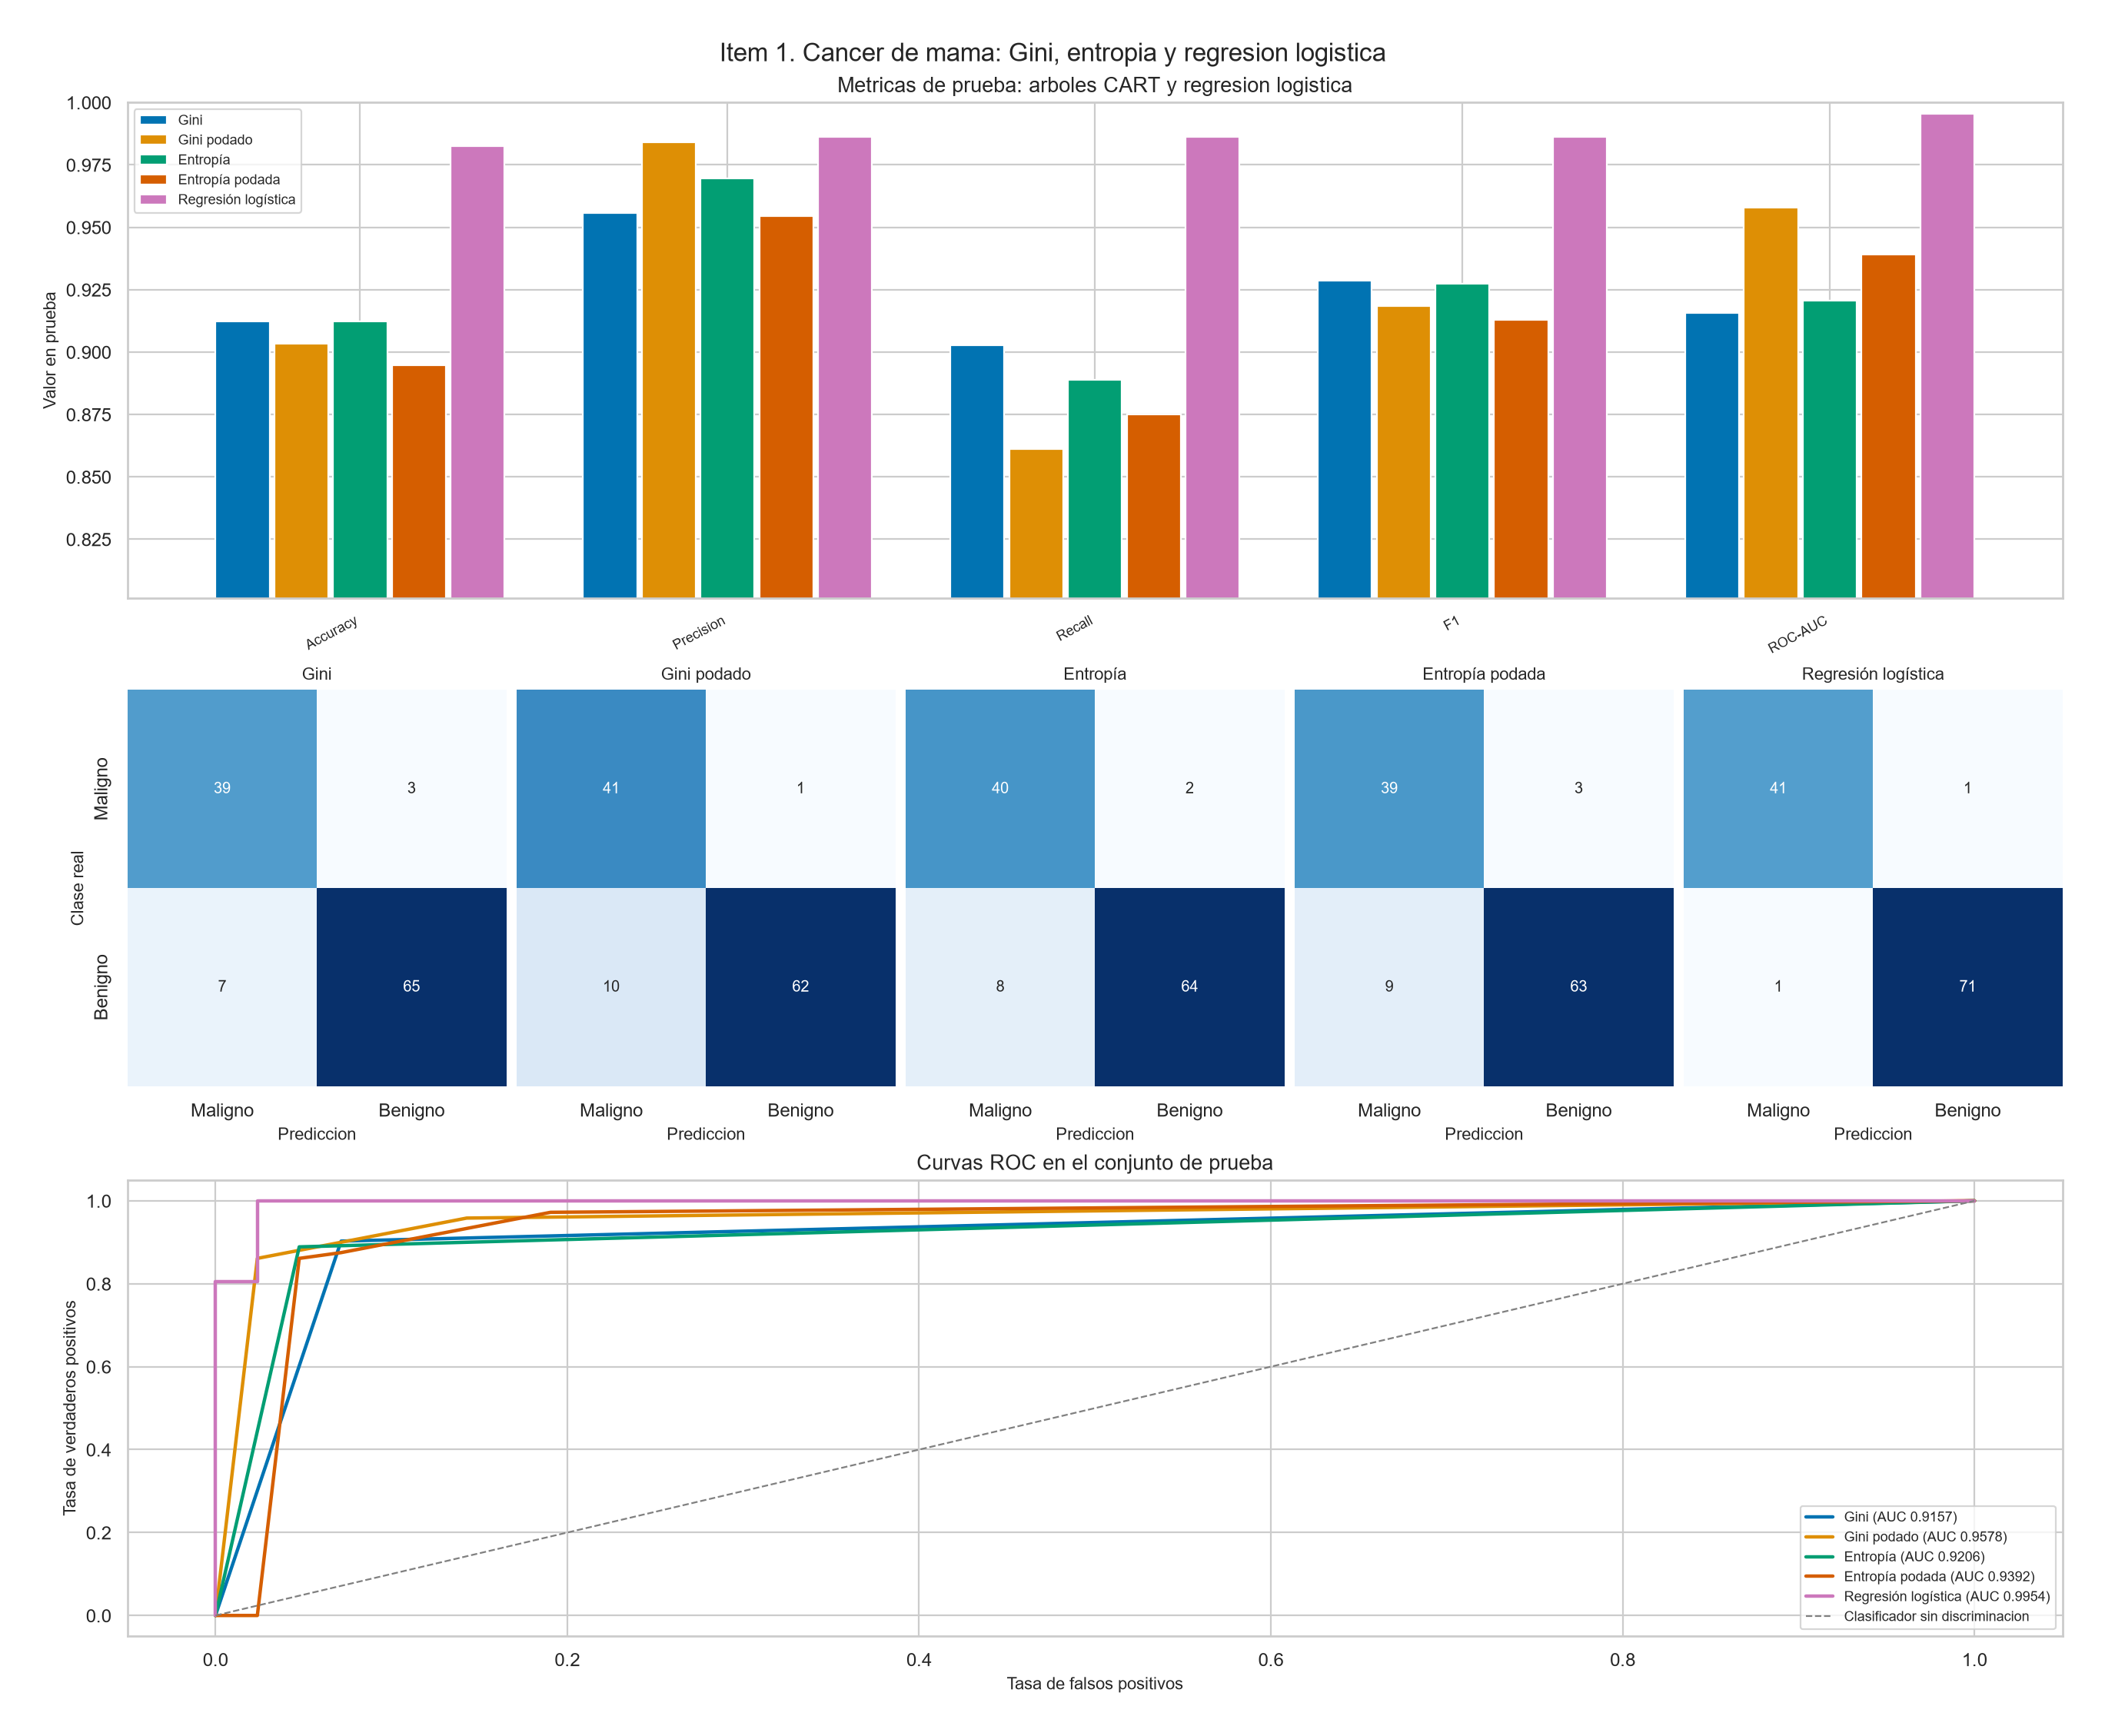

In [2]:
def show_models(models):
    frame = pd.DataFrame(
        [
            {
                'modelo': model['name'],
                'accuracy_test': model['metrics'].get('accuracy_test'),
                'f1_test': model['metrics'].get('f1_test'),
                'roc_auc_test': model['metrics'].get('roc_auc_test'),
                'r2_test': model['metrics'].get('r2_test'),
                'rmse_test': model['metrics'].get('rmse_test'),
                'cv_accuracy': model['metrics'].get('cv_accuracy_mean'),
                'cv_r2': model['metrics'].get('cv_r2_mean'),
            }
            for model in models
        ]
    )
    display(frame.round(4).fillna('no aplica'))

show_models(results['item1']['models'])
display(Image(filename='plots/item1_breast_cancer.png'))


<a id="pregunta-2"></a>

## Pregunta 2. Árboles de regresión con varias configuraciones y regresión lineal

### Indicación

> Entrene modelos de árboles de decisión con varias configuraciones de hiper parámetros usando el dataset auto_mpg, comparar su eficiencia con respecto a un modelo lineal como el Regresor Lineal. ¿Cuál es el mejor?

### Diseño del experimento y configuración de hiperparámetros

Todos los modelos ven la misma matriz: seis variables numéricas y `origin` en one-hot con referencia `europe`. Los árboles reciben esa matriz en sus unidades originales. La regresión lineal la estandariza dentro del `Pipeline`, lo que no cambia las predicciones de mínimos cuadrados y sí hace comparables los coeficientes.

Las seis configuraciones de árbol son: sin restricciones; profundidad 2; profundidad 4 con `min_samples_split=5` y `min_samples_leaf=2`; error absoluto con profundidad 5 y `min_samples_leaf=5`; poda por el `ccp_alpha` de menor RMSE de validación cruzada; y `GridSearchCV` sobre criterio, profundidad, tamaños mínimos de nodo y `max_features`.

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Árbol sin restricciones | criterion=squared_error, max_depth=sin límite, min_samples_split=2, min_samples_leaf=1, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Árbol superficial | criterion=squared_error, max_depth=2, min_samples_split=2, min_samples_leaf=1, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Árbol profundidad controlada | criterion=squared_error, max_depth=4, min_samples_split=5, min_samples_leaf=2, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Árbol error absoluto | criterion=absolute_error, max_depth=5, min_samples_leaf=5, min_samples_split=2, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Árbol poda CCP | criterion=squared_error, ccp_alpha=0.150907, random_state=42 | 35 combinaciones y 175 ajustes en 1.48 s. Criterio interno: neg_root_mean_squared_error. Mejor configuración: ccp_alpha=0.150907. |
| Árbol GridSearchCV | criterion=squared_error, max_depth=8, max_features=sqrt, min_samples_leaf=2, min_samples_split=10 | 444 combinaciones y 2220 ajustes en 31.42 s. Criterio interno: neg_root_mean_squared_error. Mejor configuración: criterion=squared_error, max_depth=8, max_features=sqrt, min_samples_leaf=2, min_samples_split=10. |
| Regresión lineal | preprocesado=one-hot de origin con referencia europe, scaler=StandardScaler, estimador=LinearRegression | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |

### Resultados

| Modelo | R² train | R² test | RMSE test | MAE test | MSE test | CV R² (media ± desv.) | CV RMSE (media ± desv.) | Profundidad | Hojas | Tiempo (ms) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Árbol sin restricciones | 1.0000 | 0.7775 | 3.3700 | 2.2962 | 11.3567 | 0.7656 ± 0.0975 | 3.6871 ± 0.5824 | 16 | 263 | 10.86 |
| Árbol superficial | 0.7573 | 0.5834 | 4.6114 | 3.4993 | 21.2654 | 0.7153 ± 0.0699 | 4.1464 ± 0.2577 | 2 | 4 | 9.36 |
| Árbol profundidad controlada | 0.8859 | 0.8145 | 3.0772 | 2.2782 | 9.4690 | 0.8036 ± 0.0550 | 3.4382 ± 0.2963 | 4 | 15 | 8.07 |
| Árbol error absoluto | 0.8966 | 0.8629 | 2.6448 | 2.0905 | 6.9952 | 0.8060 ± 0.0417 | 3.4442 ± 0.3331 | 5 | 29 | 13.39 |
| Árbol poda CCP | 0.9336 | 0.7977 | 3.2131 | 2.2556 | 10.3238 | 0.7947 ± 0.0655 | 3.4987 ± 0.2658 | 7 | 23 | 11.04 |
| Árbol GridSearchCV | 0.9254 | 0.8107 | 3.1086 | 2.0481 | 9.6632 | 0.8296 ± 0.0408 | 3.2216 ± 0.3100 | 8 | 53 | 9.78 |
| Regresión lineal | 0.8287 | 0.7923 | 3.2561 | 2.4620 | 10.6023 | 0.8188 ± 0.0143 | 3.3671 ± 0.4179 | no aplica | no aplica | 13.28 |



Coeficientes de la regresión lineal sobre variables estandarizadas (intercepto 23.5994):



| Variable estandarizada | Coeficiente |
| --- | --- |
| weight | -5.3937 |
| model_year | 2.8892 |
| displacement | 1.9898 |
| origin=usa | -1.3756 |
| horsepower | -0.8264 |
| cylinders | -0.5808 |
| origin=japan | 0.1325 |
| acceleration | 0.1187 |



![Gráfico de la pregunta 2: R², RMSE y curva de validación de max_depth en auto_mpg](plots/item2_auto_mpg.png)

### Respuesta Fundamentada: ¿Cuál es mejor?

El criterio de decisión es el menor RMSE de prueba. El desempate usa el R² de prueba y después el R² medio de validación cruzada.

El árbol sin restricciones memoriza el entrenamiento: R² train 1.0000, R² test 0.7775, RMSE test 3.3700 mpg, profundidad 16 y 263 hojas. La regresión lineal obtiene R² train 0.8287, R² test 0.7923 y RMSE test 3.2561. El árbol sin poda queda 0.1139 mpg por encima de la recta en RMSE de prueba.

El árbol superficial (max_depth = 2) muestra el otro extremo: R² test 0.5834 y RMSE test 4.6114, con profundidad 2 y 4 hojas. La curva que aísla `max_depth`, con el resto de hiperparámetros en su valor base, alcanza el menor RMSE de prueba en profundidad 6 (RMSE 3.0364, R² 0.8194). El R² de entrenamiento llega a 0.9990 en profundidad 12. A partir de ese punto el entrenamiento sigue cerrado y la prueba deja de mejorar.

**Ganador: Árbol error absoluto.** RMSE de prueba 2.6448 mpg, R² de prueba 0.8629, MAE 2.0905 y validación cruzada de R² 0.8060 ± 0.0417. El segundo modelo, Árbol profundidad controlada, tiene RMSE 3.0772 (0.4323 mpg más). La métrica de prueba selecciona a Árbol error absoluto y la validación cruzada selecciona a Árbol GridSearchCV en R². El ganador de la pregunta es el de la prueba, y esta discrepancia queda registrada. Prueba t pareada sobre los 5 pliegues de R²: la media de Árbol error absoluto menos Árbol profundidad controlada es 0.0024, t = 0.162, p = 0.8795. El promedio de pliegues favorece a Árbol error absoluto. Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

El ganador supera a la regresión lineal porque un árbol regularizado parte el espacio de `weight`, `horsepower`, `displacement` y `model_year` en regiones donde la pendiente de mpg cambia. Esas interacciones no caben en un único hiperplano. Las importancias relativas del ganador se concentran en displacement (0.565), horsepower (0.242), weight (0.118). La regresión lineal, aun así, ya explica una parte grande de la varianza (R² de prueba 0.7923) y sus mayores coeficientes estandarizados son weight (-5.394), model_year (2.889), displacement (1.990), origin=usa (-1.376), horsepower (-0.826).

La búsqueda del árbol optimizado evaluó 444 combinaciones (2220 ajustes) en 31.42 s. La configuración elegida es criterion=squared_error, max_depth=8, max_features=sqrt, min_samples_leaf=2, min_samples_split=10.


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Árbol sin restricciones,no aplica,no aplica,no aplica,0.7775,3.3700,no aplica,0.7656
1,Árbol superficial,no aplica,no aplica,no aplica,0.5834,4.6114,no aplica,0.7153
2,Árbol profundidad controlada,no aplica,no aplica,no aplica,0.8145,3.0772,no aplica,0.8036
3,Árbol error absoluto,no aplica,no aplica,no aplica,0.8629,2.6448,no aplica,0.8060
4,Árbol poda CCP,no aplica,no aplica,no aplica,0.7977,3.2131,no aplica,0.7947
5,Árbol GridSearchCV,no aplica,no aplica,no aplica,0.8107,3.1086,no aplica,0.8296
6,Regresión lineal,no aplica,no aplica,no aplica,0.7923,3.2561,no aplica,0.8188


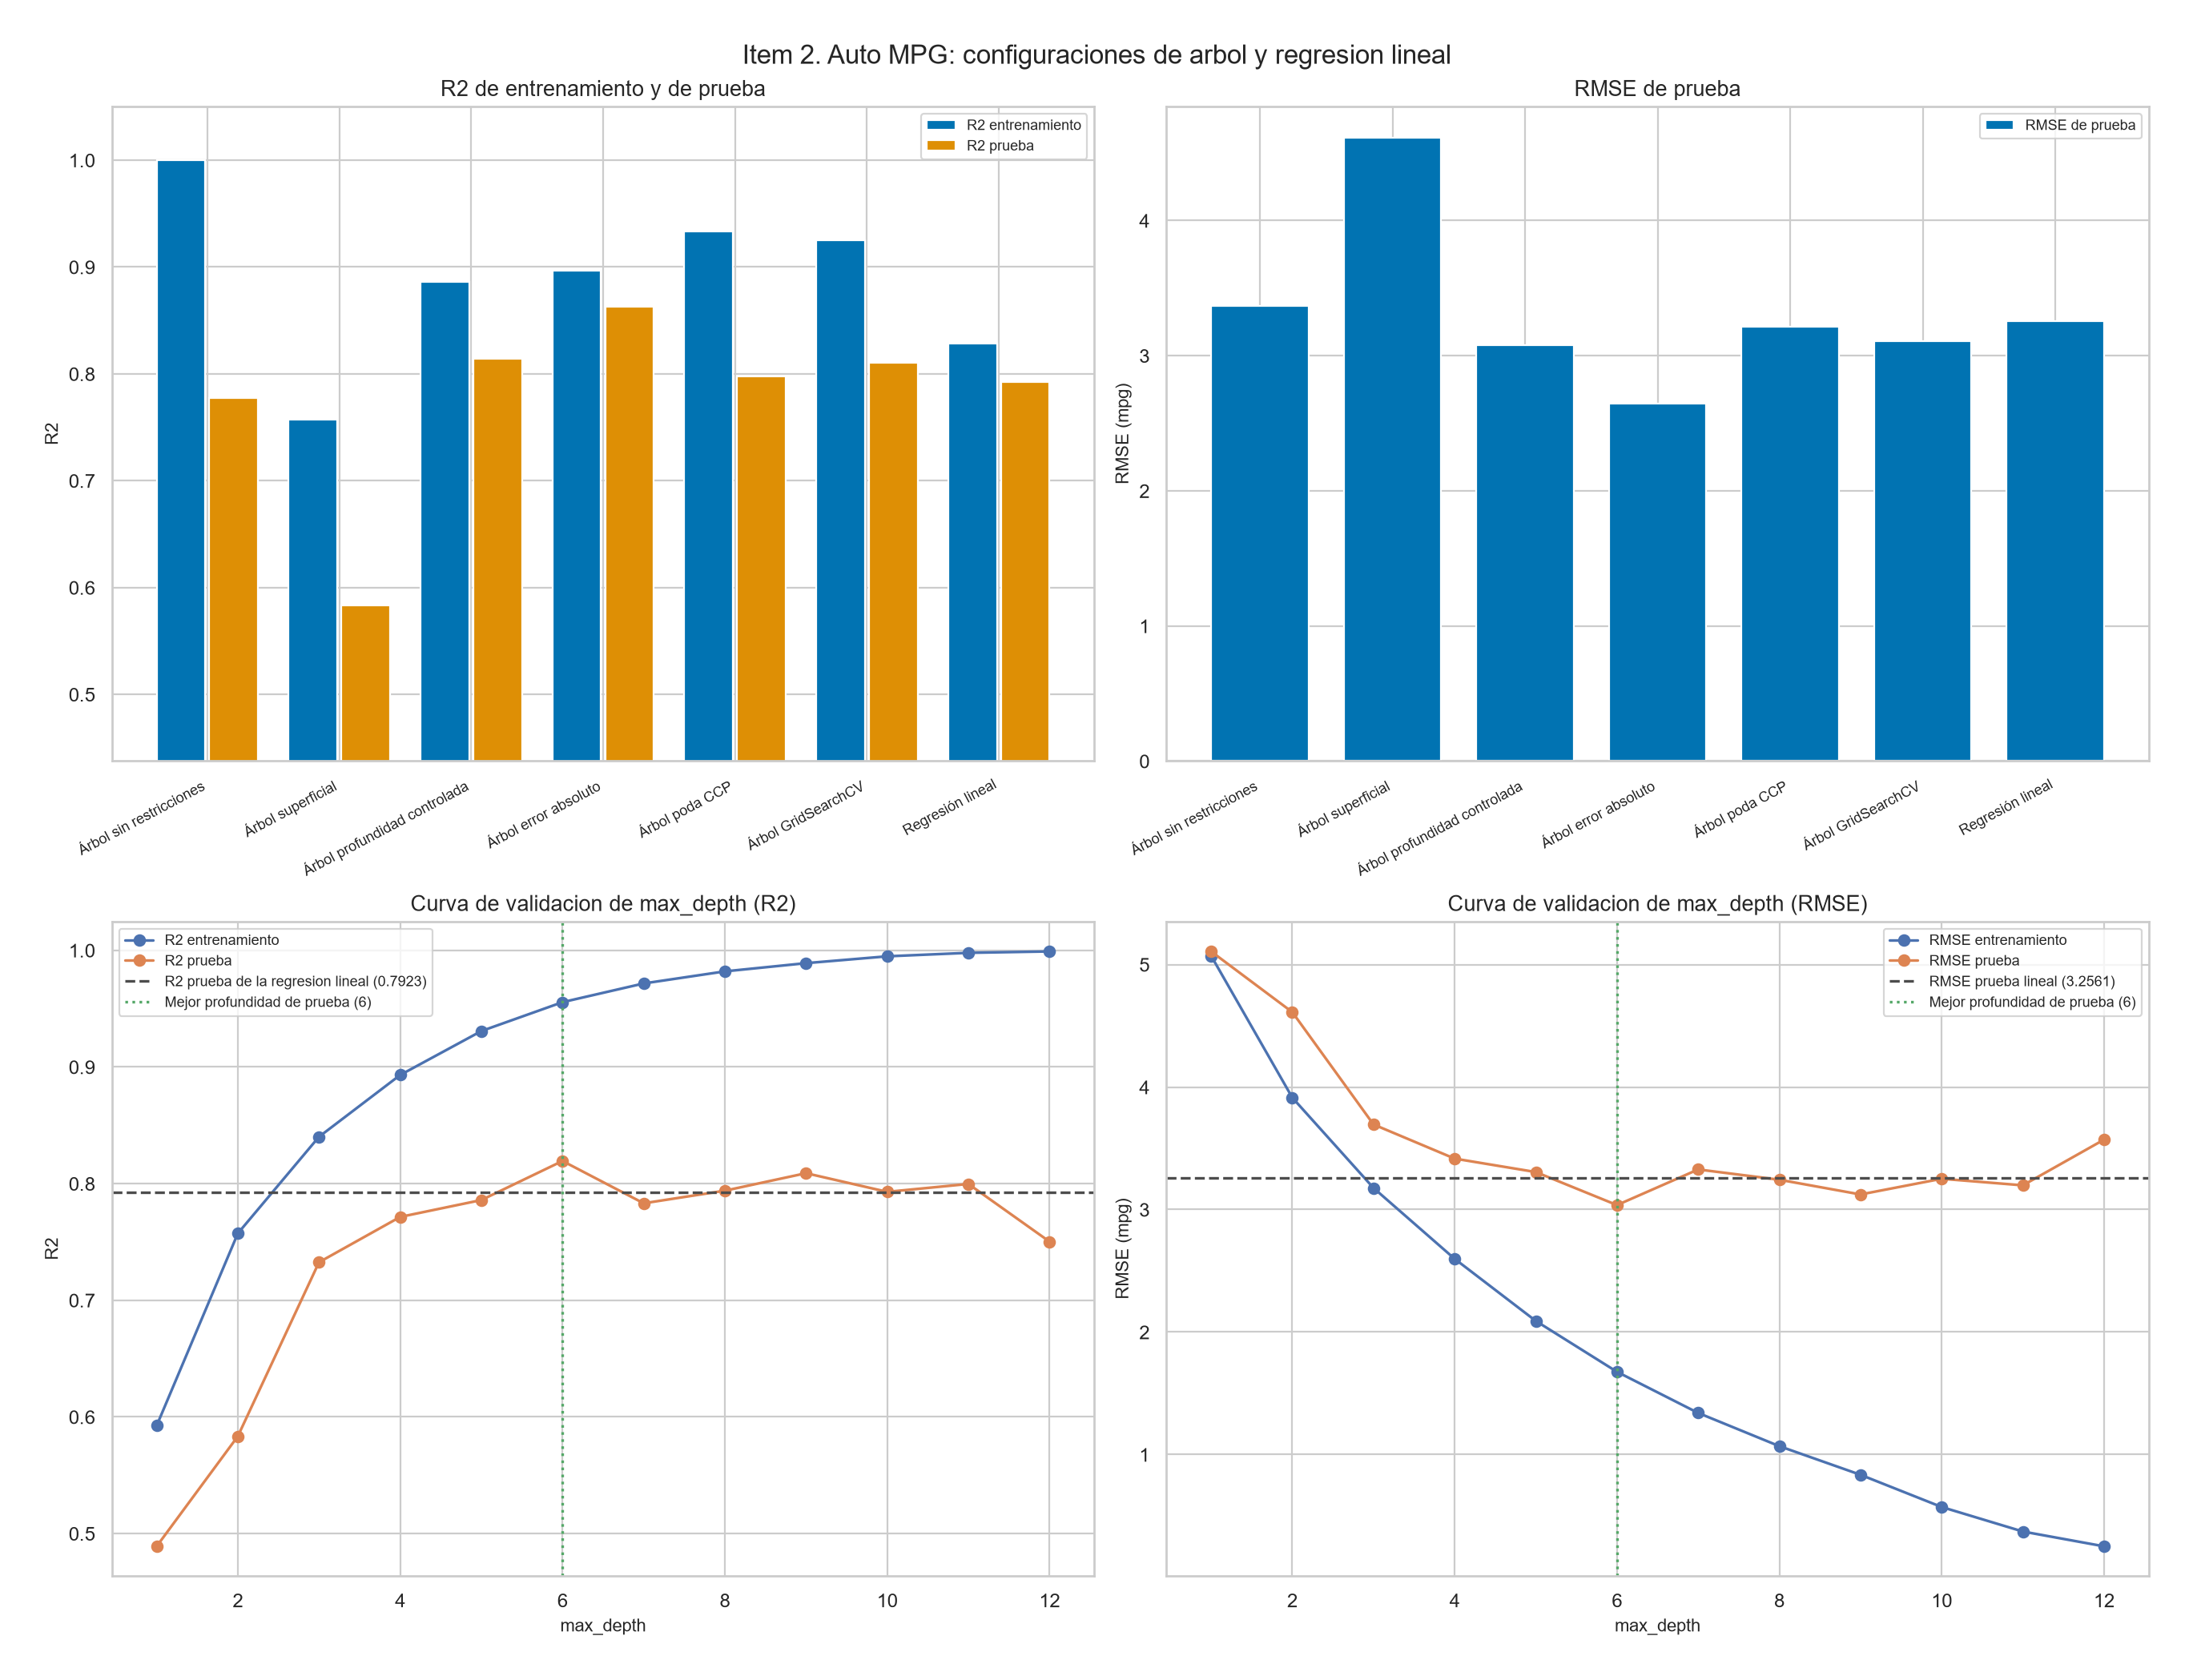

In [3]:
show_models(results['item2']['models'])
display(Image(filename='plots/item2_auto_mpg.png'))


<a id="pregunta-3"></a>

## Pregunta 3. Ensamble clasificador frente a un modelo individual

### Indicación

> Entrene un modelo ensemble clasificador, y compare su eficiencia con respecto a un modelo individual. ¿Cuál es mejor?

### Diseño del experimento y configuración de hiperparámetros

Los modelos individuales son un árbol de decisión, un SVC con kernel RBF y probabilidades calibradas, un k-NN con 5 vecinos y la regresión logística L2. SVC, k-NN y logística se escalan dentro de un `Pipeline`. El árbol no se escala porque sus cortes son invariantes a una transformación monótona por variable.

Los ensambles reutilizan esas cuatro bases en voting duro, voting suave y stacking con meta-aprendiz logístico y 5 pliegues internos. AdaBoost suma 50 tocones y el gradient boosting usa su configuración base (100 árboles, profundidad 3, learning rate 0.1).

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Árbol de decisión | criterion=gini, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| SVC | kernel=rbf, probability=sí, scaler=StandardScaler, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| k-NN | n_neighbors=5, scaler=StandardScaler | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Regresión logística | penalty=L2, l1_ratio=0, C=1, max_iter=10000, scaler=StandardScaler, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Voting duro | voting=hard, bases=arbol, SVC, k-NN, regresion logistica | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Voting suave | voting=soft, bases=arbol, SVC, k-NN, regresion logistica | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Stacking | final_estimator=regresion logistica L2, cv=StratifiedKFold de 5 pliegues, passthrough=no | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| AdaBoost | n_estimators=50, learning_rate=1, estimator_max_depth=1, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Gradient Boosting | n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |

El voting duro no emite probabilidades, de modo que su ROC-AUC queda marcado como no aplica. El ranking principal usa el ROC-AUC de los modelos que sí producen probabilidades. El accuracy del voting duro se discute de forma explícita.

### Resultados

| Modelo | Acc. train | Acc. test | Precisión | Recall | F1 | ROC-AUC | Recall maligno | CV accuracy (media ± desv.) | Profundidad | Hojas | Tiempo (ms) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Árbol de decisión | 1.0000 | 0.9123 | 0.9559 | 0.9028 | 0.9286 | 0.9157 | 0.9286 | 0.9165 ± 0.0179 | 7 | 19 | 13.11 |
| SVC | 0.9824 | 0.9825 | 0.9861 | 0.9861 | 0.9861 | 0.9950 | 0.9762 | 0.9692 ± 0.0146 | no aplica | no aplica | 37.25 |
| k-NN | 0.9736 | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9788 | 0.9286 | 0.9626 ± 0.0112 | no aplica | no aplica | 6.09 |
| Regresión logística | 0.9890 | 0.9825 | 0.9861 | 0.9861 | 0.9861 | 0.9954 | 0.9762 | 0.9780 ± 0.0098 | no aplica | no aplica | 12.53 |
| Voting duro | 0.9868 | 0.9825 | 0.9861 | 0.9861 | 0.9861 | no aplica | 0.9762 | 0.9670 ± 0.0120 | no aplica | no aplica | 66.50 |
| Voting suave | 0.9934 | 0.9737 | 0.9726 | 0.9861 | 0.9793 | 0.9911 | 0.9524 | 0.9758 ± 0.0128 | no aplica | no aplica | 74.44 |
| Stacking | 0.9912 | 0.9737 | 0.9726 | 0.9861 | 0.9793 | 0.9917 | 0.9524 | 0.9780 ± 0.0098 | no aplica | no aplica | 507.46 |
| AdaBoost | 1.0000 | 0.9561 | 0.9467 | 0.9861 | 0.9660 | 0.9825 | 0.9048 | 0.9670 ± 0.0197 | no aplica | no aplica | 253.39 |
| Gradient Boosting | 1.0000 | 0.9561 | 0.9467 | 0.9861 | 0.9660 | 0.9907 | 0.9048 | 0.9516 ± 0.0149 | no aplica | no aplica | 634.48 |



![Gráfico de la pregunta 3: modelos individuales y ensambles de clasificación](plots/item3_ensemble_clf.png)

### Respuesta Fundamentada: ¿Cuál es mejor?

El criterio de decisión entre modelos con probabilidades es el ROC-AUC de prueba. El desempate usa F1, accuracy de prueba y la media de accuracy en validación cruzada.

El mejor ensamble (Stacking, ROC-AUC 0.9917) y el mejor individual (Regresión logística, ROC-AUC 0.9954) quedan a 0.0036 de ROC-AUC. Frente al árbol individual, el ensamble sí abre una ventaja de 0.0761 de ROC-AUC y de 6.14 puntos porcentuales de accuracy.

**Ganador: Regresión logística.** ROC-AUC de prueba 0.9954, F1 0.9861, accuracy 0.9825 y validación cruzada 0.9780 ± 0.0098. El segundo, SVC, queda en ROC-AUC 0.9950 (diferencia de 0.03 puntos). El margen de ROC-AUC es ajustado: la diferencia es menor que 0.005 y conviene leerla junto al F1, la accuracy y el tiempo de ajuste. El líder por accuracy de prueba, contando también al voting duro, es SVC con 0.9825. El voting duro alcanza accuracy de prueba 0.9825 y F1 0.9861. La validación cruzada señala al mismo modelo, Regresión logística, como líder de ROC-AUC. Prueba t pareada sobre los 5 pliegues de ROC-AUC: la media de Regresión logística menos SVC es 0.0003, t = 0.688, p = 0.5291. El promedio de pliegues favorece a Regresión logística. Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

El stacking entrena a las bases en pliegues internos y deja que una regresión logística meta aprenda qué modelo pesa más en cada región del espacio. Corrige errores sistemáticos que una votación con pesos fijos no corrige.

El árbol individual queda en accuracy de entrenamiento 1.0000 y de prueba 0.9123, con profundidad 7 y 19 hojas. Esa brecha es la varianza que el ensamble ataca. La regresión logística individual sigue en ROC-AUC 0.9954 y F1 0.9861: cualquier ensamble tiene que mejorar esa base lineal, no solo al árbol.


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Árbol de decisión,0.9123,0.9286,0.9157,no aplica,no aplica,0.9165,no aplica
1,SVC,0.9825,0.9861,0.995,no aplica,no aplica,0.9692,no aplica
2,k-NN,0.9561,0.9655,0.9788,no aplica,no aplica,0.9626,no aplica
3,Regresión logística,0.9825,0.9861,0.9954,no aplica,no aplica,0.9780,no aplica
4,Voting duro,0.9825,0.9861,no aplica,no aplica,no aplica,0.9670,no aplica
5,Voting suave,0.9737,0.9793,0.9911,no aplica,no aplica,0.9758,no aplica
6,Stacking,0.9737,0.9793,0.9917,no aplica,no aplica,0.9780,no aplica
7,AdaBoost,0.9561,0.9660,0.9825,no aplica,no aplica,0.9670,no aplica
8,Gradient Boosting,0.9561,0.9660,0.9907,no aplica,no aplica,0.9516,no aplica


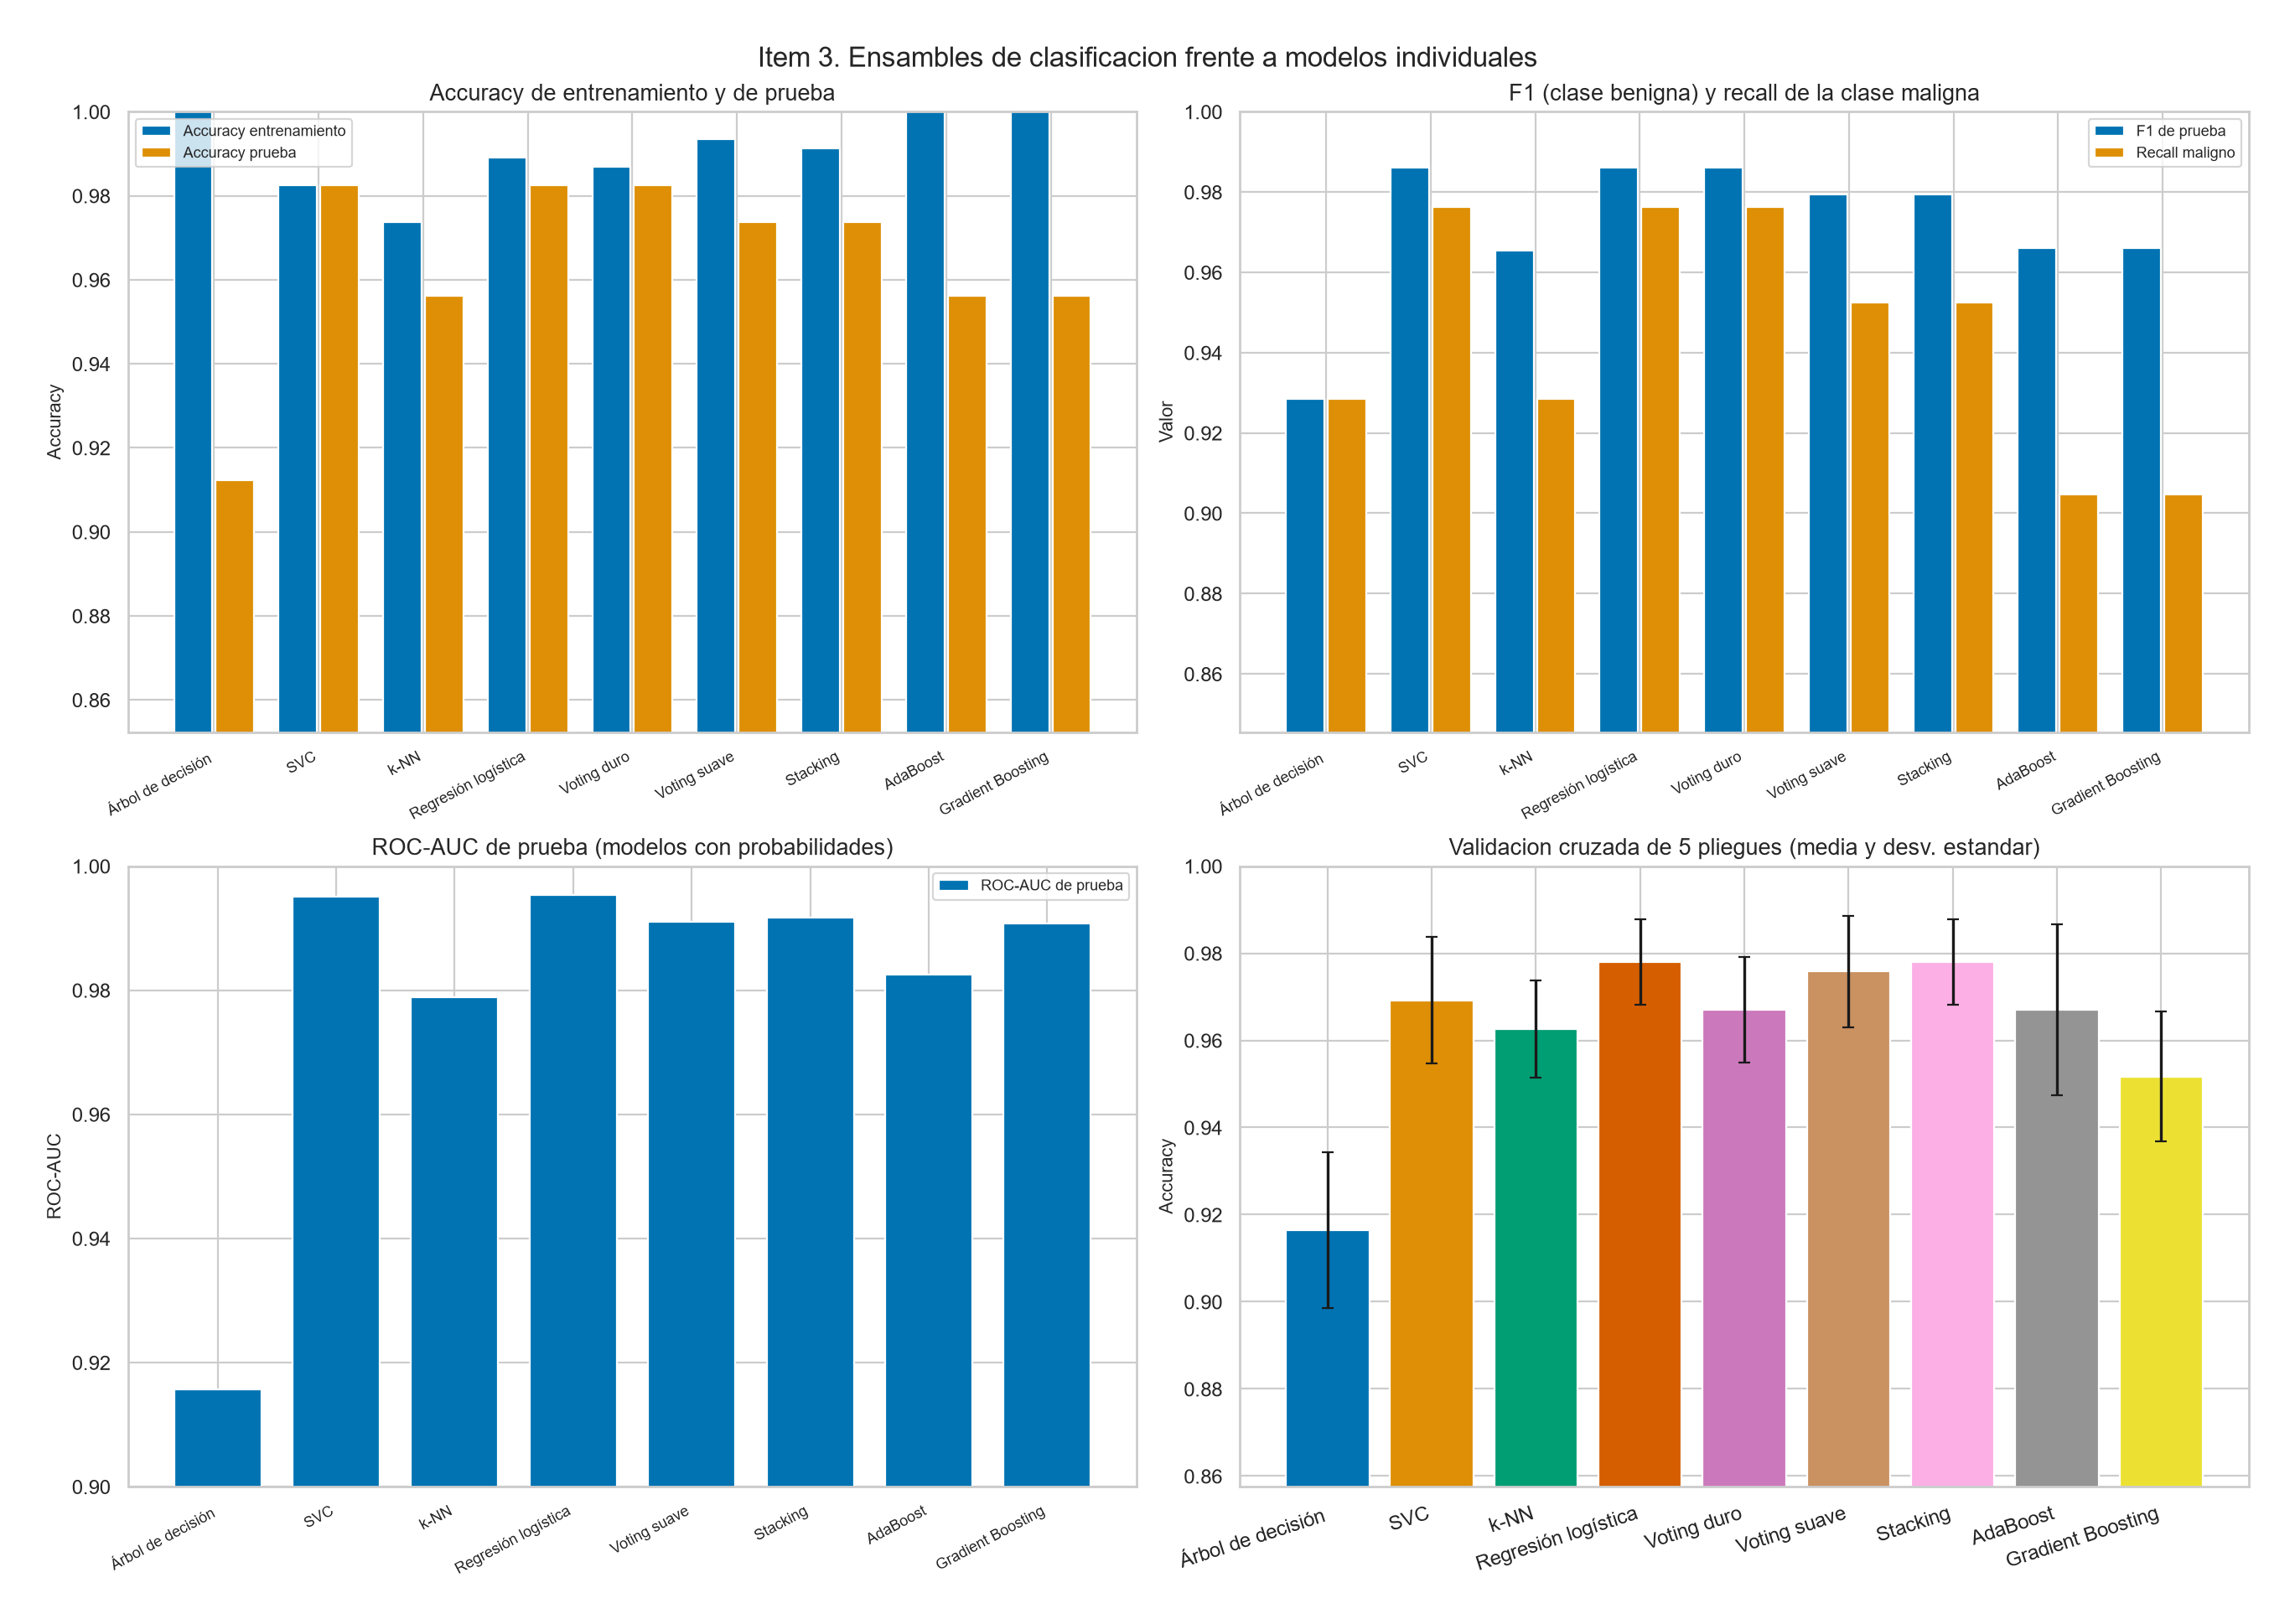

In [4]:
show_models(results['item3']['models'])
display(Image(filename='plots/item3_ensemble_clf.png'))


<a id="pregunta-4"></a>

## Pregunta 4. Bagging clasificador y regresor frente al modelo individual

### Indicación

> Entrene un modelo bagging regresor o clasificador y compare su eficiencia con respecto a un modelo individual. ¿Cuál es el mejor?

### Diseño del experimento y configuración de hiperparámetros

Escenario A, cáncer de mama: un `DecisionTreeClassifier` individual frente a `BaggingClassifier` con árboles profundos, `n_estimators` en {10, 50, 100, 200}, `max_samples=1.0`, `bootstrap=True`, `oob_score=True` y `random_state=42`.

Escenario B, auto_mpg: el mismo contraste con `DecisionTreeRegressor`. El one-hot de `origin` vive en un `Pipeline` anterior al bagging, porque el ensamble convierte las filas a matriz y un transformador por nombre de columna no puede ir dentro de cada muestra bootstrap. El preprocesado se ajusta en cada pliegue de validación y en el entrenamiento completo, nunca con el conjunto de prueba.

Clasificación:

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Árbol individual | criterion=gini, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (10) | n_estimators=10, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeClassifier, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (50) | n_estimators=50, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeClassifier, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (100) | n_estimators=100, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeClassifier, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (200) | n_estimators=200, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeClassifier, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |

Regresión:

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Árbol individual | criterion=squared_error, max_depth=sin límite, min_samples_split=2, min_samples_leaf=1, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (10) | n_estimators=10, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeRegressor, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (50) | n_estimators=50, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeRegressor, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (100) | n_estimators=100, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeRegressor, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Bagging (200) | n_estimators=200, max_samples=1, bootstrap=sí, oob_score=sí, base=DecisionTreeRegressor, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |

### Resultados

Escenario A. Clasificación en cáncer de mama:



| Modelo | Acc. train | Acc. test | Precisión | Recall | F1 | ROC-AUC | Recall maligno | CV accuracy (media ± desv.) | Profundidad | Hojas | Tiempo (ms) | OOB accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Árbol individual | 1.0000 | 0.9123 | 0.9559 | 0.9028 | 0.9286 | 0.9157 | 0.9286 | 0.9165 ± 0.0179 | 7 | 19 | 12.01 | no aplica |
| Bagging (10) | 0.9956 | 0.9298 | 0.9444 | 0.9444 | 0.9444 | 0.9899 | 0.9048 | 0.9495 ± 0.0112 | no aplica | no aplica | 90.64 | 0.9297 |
| Bagging (50) | 1.0000 | 0.9386 | 0.9452 | 0.9583 | 0.9517 | 0.9922 | 0.9048 | 0.9516 ± 0.0204 | no aplica | no aplica | 552.93 | 0.9516 |
| Bagging (100) | 1.0000 | 0.9386 | 0.9452 | 0.9583 | 0.9517 | 0.9927 | 0.9048 | 0.9516 ± 0.0192 | no aplica | no aplica | 894.52 | 0.9560 |
| Bagging (200) | 1.0000 | 0.9474 | 0.9583 | 0.9583 | 0.9583 | 0.9924 | 0.9286 | 0.9516 ± 0.0215 | no aplica | no aplica | 1805.80 | 0.9648 |



Escenario B. Regresión en auto_mpg:



| Modelo | R² train | R² test | RMSE test | MAE test | MSE test | CV R² (media ± desv.) | CV RMSE (media ± desv.) | Profundidad | Hojas | Tiempo (ms) | OOB R² |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Árbol individual | 1.0000 | 0.7775 | 3.3700 | 2.2962 | 11.3567 | 0.7656 ± 0.0975 | 3.6871 ± 0.5824 | 16 | 263 | 12.66 | no aplica |
| Bagging (10) | 0.9710 | 0.8534 | 2.7358 | 1.9773 | 7.4845 | 0.8592 ± 0.0309 | 2.9265 ± 0.1796 | no aplica | no aplica | 57.30 | 0.8349 |
| Bagging (50) | 0.9795 | 0.8848 | 2.4252 | 1.7292 | 5.8814 | 0.8684 ± 0.0305 | 2.8336 ± 0.2845 | no aplica | no aplica | 236.20 | 0.8615 |
| Bagging (100) | 0.9809 | 0.8871 | 2.4004 | 1.7112 | 5.7617 | 0.8653 ± 0.0326 | 2.8649 ± 0.2940 | no aplica | no aplica | 453.20 | 0.8676 |
| Bagging (200) | 0.9821 | 0.8880 | 2.3911 | 1.6713 | 5.7172 | 0.8636 ± 0.0324 | 2.8839 ± 0.2961 | no aplica | no aplica | 986.01 | 0.8692 |



![Gráfico de la pregunta 4: ganancia del bagging y convergencia al aumentar el número de árboles](plots/item4_bagging.png)

### Respuesta Fundamentada: ¿Cuál es mejor?

En clasificación gana el mayor accuracy de prueba, con desempate por F1 y ROC-AUC. En regresión gana el menor RMSE de prueba.

En cáncer de mama, el árbol individual tiene accuracy de prueba 0.9123, F1 0.9286 y ROC-AUC 0.9157, con accuracy de entrenamiento 1.0000. El bagging de referencia, con 100 árboles, sube el accuracy de prueba a 0.9386, el F1 a 0.9517 y el ROC-AUC a 0.9927. Su OOB accuracy es 0.9560 y su validación cruzada es 0.9516 ± 0.0192. La mejor cantidad de árboles en la prueba es Bagging (200), con accuracy 0.9474 (3.51 puntos porcentuales sobre el árbol) y F1 0.9583 (2.98 puntos porcentuales). **En clasificación el mejor es Bagging (200).** Prueba t pareada sobre los 5 pliegues de accuracy: la media de Bagging (200) menos Árbol individual es 0.0352, t = 3.301, p = 0.0299. El promedio de pliegues favorece a Bagging (200). Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

En el conjunto de prueba, la correlación media entre las predicciones de los 100 miembros de Bagging (100) es 0.809. Bajo el modelo de equicorrelación, el factor de varianza del promedio es 0.811. Si los miembros fueran independientes, ese factor sería 0.0100. La correlación observada impide que la varianza caiga en la proporción ideal 1/B.

En auto_mpg, el árbol individual pasa de R² train 1.0000 a R² test 0.7775, con RMSE de prueba 3.3700 y MAE 2.2962. El bagging de 100 árboles obtiene R² test 0.8871, RMSE 2.4004, MAE 1.7112 y OOB R² 0.8676. Su validación cruzada de RMSE es 2.8649 ± 0.2940 y la de R² es 0.8653 ± 0.0326. La mejor cantidad de árboles por RMSE de prueba es Bagging (200): RMSE 2.3911 y R² 0.8880. La reducción de RMSE frente al árbol individual es 0.9789 mpg (29.05% del RMSE del árbol). **En regresión el mejor es Bagging (200).** Prueba t pareada sobre los 5 pliegues de R²: la media de Bagging (200) menos Árbol individual es 0.0980, t = 2.615, p = 0.0591. El promedio de pliegues favorece a Bagging (200). Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

En el conjunto de prueba, la correlación media entre las predicciones de los 100 miembros de Bagging (100) es 0.864. Bajo el modelo de equicorrelación, el factor de varianza del promedio es 0.865. Si los miembros fueran independientes, ese factor sería 0.0100. La correlación observada impide que la varianza caiga en la proporción ideal 1/B.

El promedio de B predictores con varianza σ² y correlación ρ tiene varianza ρσ² + (1 − ρ)σ² / B. Con independencia, ρ = 0 y la varianza queda en σ² / B. El muestreo bootstrap con reemplazo genera muestras distintas; promediar los B árboles profundos deja el sesgo cerca del de un solo árbol y recorta la varianza en la medida en que esas muestras no produzcan los mismos errores. La correlación estimada arriba muestra que los árboles no son independientes, así que la ganancia empírica es real y menor que la del caso ρ = 0.

$$
\operatorname{Var}(\bar{X})=\rho\sigma^{2}+\frac{(1-\rho)\sigma^{2}}{B}
$$

Cuando los árboles son independientes, \(\rho = 0\) y la expresión se reduce a \(\sigma^{2}/B\).


Pregunta 4. Clasificación en cáncer de mama


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Árbol individual,0.9123,0.9286,0.9157,no aplica,no aplica,0.9165,no aplica
1,Bagging (10),0.9298,0.9444,0.9899,no aplica,no aplica,0.9495,no aplica
2,Bagging (50),0.9386,0.9517,0.9922,no aplica,no aplica,0.9516,no aplica
3,Bagging (100),0.9386,0.9517,0.9927,no aplica,no aplica,0.9516,no aplica
4,Bagging (200),0.9474,0.9583,0.9924,no aplica,no aplica,0.9516,no aplica


Regresion


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Árbol individual,no aplica,no aplica,no aplica,0.7775,3.3700,no aplica,0.7656
1,Bagging (10),no aplica,no aplica,no aplica,0.8534,2.7358,no aplica,0.8592
2,Bagging (50),no aplica,no aplica,no aplica,0.8848,2.4252,no aplica,0.8684
3,Bagging (100),no aplica,no aplica,no aplica,0.8871,2.4004,no aplica,0.8653
4,Bagging (200),no aplica,no aplica,no aplica,0.8880,2.3911,no aplica,0.8636


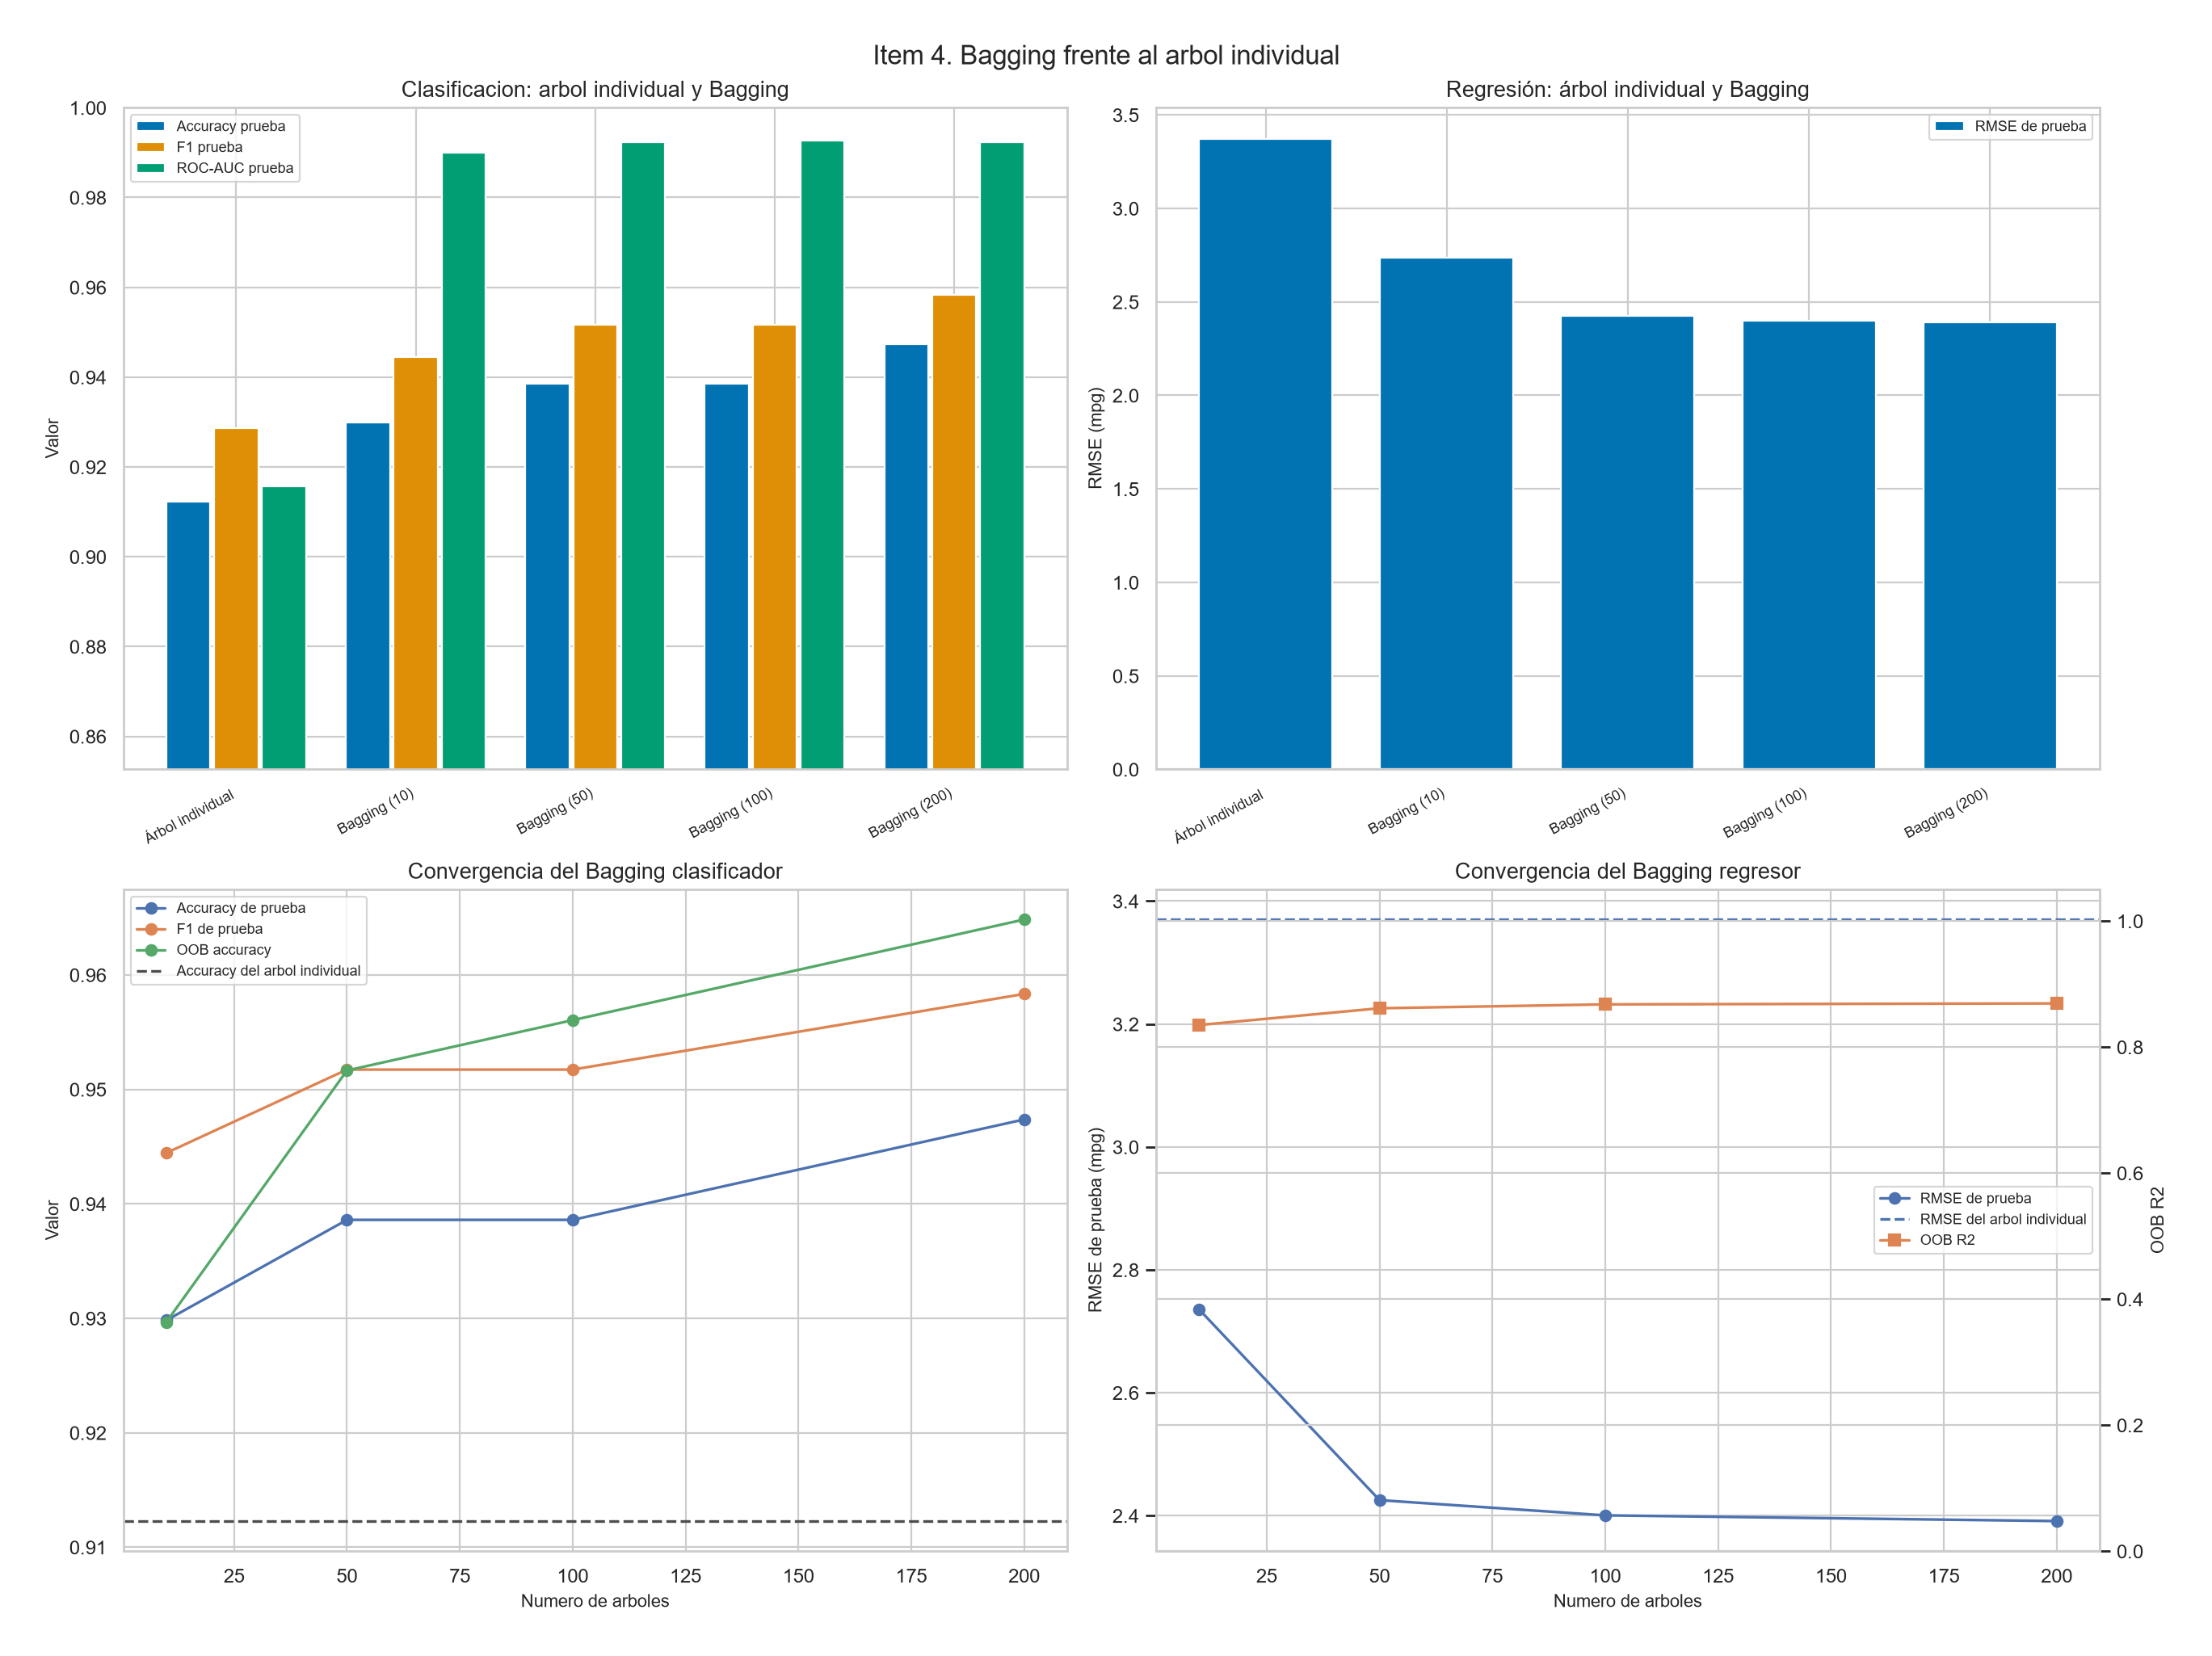

In [5]:
print('Pregunta 4. Clasificación en cáncer de mama')
show_models(results['item4']['classification']['models'])
print('Pregunta 4. Regresión en auto_mpg')
show_models(results['item4']['regression']['models'])
display(Image(filename='plots/item4_bagging.png'))


<a id="pregunta-5"></a>

## Pregunta 5. Random Forest frente a XGBoost

### Indicación

> Entrene un modelo RandomForest y compare su eficiencia con respecto a un modelo XGBoost. ¿Cuál es mejor?

### Diseño del experimento y configuración de hiperparámetros

En clasificación se comparan `RandomForestClassifier(n_estimators=100, random_state=42)` y `XGBClassifier(n_estimators=100, learning_rate=0.1, eval_metric='logloss', random_state=42)`, cada uno en versión base y en versión elegida por `GridSearchCV`. La búsqueda de Random Forest cubre número de árboles, profundidad, tamaño mínimo de hoja y `max_features`. La de XGBoost cubre número de árboles, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree` y `reg_lambda`. El criterio interno es el ROC-AUC.

En regresión el esquema es el mismo con `RandomForestRegressor` y `XGBRegressor`, sobre la matriz ya codificada de auto_mpg. El Random Forest base de regresión usa el valor por omisión de scikit-learn, `max_features=1.0` (todas las variables). El de clasificación usa `sqrt`. La búsqueda de regresión puede elegir `sqrt` o la mitad de las variables si eso baja el RMSE. El criterio interno es el RMSE.

Clasificación:

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Random Forest base | n_estimators=100, max_features=sqrt, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Random Forest optimizado | max_depth=4, max_features=sqrt, min_samples_leaf=1, n_estimators=200 | 48 combinaciones y 240 ajustes en 41.31 s. Criterio interno: roc_auc. Mejor configuración: max_depth=4, max_features=sqrt, min_samples_leaf=1, n_estimators=200. |
| XGBoost base | n_estimators=100, learning_rate=0.1, eval_metric=logloss, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| XGBoost optimizado | colsample_bytree=1, learning_rate=0.2, max_depth=2, n_estimators=200, reg_lambda=5, subsample=0.8 | 192 combinaciones y 960 ajustes en 71.18 s. Criterio interno: roc_auc. Mejor configuración: colsample_bytree=1, learning_rate=0.2, max_depth=2, n_estimators=200, reg_lambda=5, subsample=0.8. |

Regresión:

| Modelo | Configuración | Búsqueda |
| --- | --- | --- |
| Random Forest base | n_estimators=100, max_features=1, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| Random Forest optimizado | max_depth=16, max_features=1, min_samples_leaf=1, n_estimators=100 | 90 combinaciones y 450 ajustes en 36.91 s. Criterio interno: neg_root_mean_squared_error. Mejor configuración: max_depth=16, max_features=1, min_samples_leaf=1, n_estimators=100. |
| XGBoost base | n_estimators=100, learning_rate=0.1, random_state=42 | Ajuste directo sobre el entrenamiento, sin búsqueda de hiperparámetros. |
| XGBoost optimizado | colsample_bytree=0.8, learning_rate=0.05, max_depth=2, n_estimators=200, reg_lambda=1, subsample=0.8 | 192 combinaciones y 960 ajustes en 5.22 s. Criterio interno: neg_root_mean_squared_error. Mejor configuración: colsample_bytree=0.8, learning_rate=0.05, max_depth=2, n_estimators=200, reg_lambda=1, subsample=0.8. |

### Resultados

Clasificación en cáncer de mama:



| Modelo | Acc. train | Acc. test | Precisión | Recall | F1 | ROC-AUC | Recall maligno | CV accuracy (media ± desv.) | Profundidad | Hojas | Tiempo (ms) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Random Forest base | 1.0000 | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9937 | 0.9286 | 0.9626 ± 0.0179 | no aplica | no aplica | 361.36 |
| Random Forest optimizado | 0.9934 | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9927 | 0.9286 | 0.9560 ± 0.0120 | no aplica | no aplica | 866.65 |
| XGBoost base | 1.0000 | 0.9474 | 0.9459 | 0.9722 | 0.9589 | 0.9937 | 0.9048 | 0.9648 ± 0.0162 | no aplica | no aplica | 1997.92 |
| XGBoost optimizado | 1.0000 | 0.9561 | 0.9467 | 0.9861 | 0.9660 | 0.9914 | 0.9048 | 0.9736 ± 0.0226 | no aplica | no aplica | 176.28 |



Regresión en auto_mpg:



| Modelo | R² train | R² test | RMSE test | MAE test | MSE test | CV R² (media ± desv.) | CV RMSE (media ± desv.) | Profundidad | Hojas | Tiempo (ms) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Random Forest base | 0.9809 | 0.8875 | 2.3966 | 1.7064 | 5.7435 | 0.8667 ± 0.0305 | 2.8535 ± 0.2911 | no aplica | no aplica | 407.54 |
| Random Forest optimizado | 0.9809 | 0.8875 | 2.3960 | 1.7061 | 5.7409 | 0.8667 ± 0.0304 | 2.8534 ± 0.2907 | no aplica | no aplica | 109.46 |
| XGBoost base | 0.9987 | 0.8556 | 2.7145 | 1.8818 | 7.3683 | 0.8370 ± 0.0445 | 3.1265 ± 0.1852 | no aplica | no aplica | 41.88 |
| XGBoost optimizado | 0.9361 | 0.8749 | 2.5265 | 1.8821 | 6.3831 | 0.8671 ± 0.0373 | 2.8296 ± 0.2216 | no aplica | no aplica | 17.55 |



Importancias relativas del Random Forest optimizado en clasificación:



| Puesto | Variable | Importancia relativa |
| --- | --- | --- |
| 1 | worst perimeter | 0.1385 |
| 2 | worst area | 0.1289 |
| 3 | worst concave points | 0.1116 |
| 4 | mean concave points | 0.0987 |
| 5 | worst radius | 0.0974 |
| 6 | mean radius | 0.0614 |
| 7 | mean perimeter | 0.0575 |
| 8 | mean area | 0.0498 |



Importancias relativas de XGBoost optimizado en clasificación:



| Puesto | Variable | Importancia relativa |
| --- | --- | --- |
| 1 | worst radius | 0.2944 |
| 2 | worst perimeter | 0.2379 |
| 3 | worst concave points | 0.1086 |
| 4 | mean concave points | 0.0973 |
| 5 | concavity error | 0.0519 |
| 6 | mean area | 0.0258 |
| 7 | perimeter error | 0.0234 |
| 8 | mean texture | 0.0180 |



![Gráfico de la pregunta 5: métricas de clasificación y regresión e importancias de Random Forest y XGBoost](plots/item5_rf_vs_xgboost.png)

### Respuesta Fundamentada: ¿Cuál es mejor?

Random Forest promedia árboles profundos entrenados en paralelo. Cada árbol ve una muestra bootstrap y, en clasificación, un subconjunto de variables de tamaño cercano a la raíz cuadrada de p. Ese submuestreo baja la correlación entre árboles y, con ella, la varianza del promedio. XGBoost suma árboles en serie. En cada paso usa una aproximación de Taylor de segundo orden de la pérdida y penaliza la norma de los pesos de las hojas con regularización L2 (`reg_lambda`) y, si se activa, L1. Por eso puede reducir sesgo y varianza a la vez, a cambio de más sensibilidad al learning rate y a la profundidad.

**En clasificación gana Random Forest base.** ROC-AUC de prueba 0.9937, F1 0.9655, accuracy 0.9561 y validación cruzada 0.9626 ± 0.0179. XGBoost base queda en ROC-AUC 0.9937 (diferencia de 0.00 puntos). El ROC-AUC de prueba empata en la práctica, así que el desempate lo resuelven el F1 y la accuracy. El ajuste final de Random Forest base tardó 361.36 ms y el de XGBoost base 1997.92 ms. La métrica de prueba selecciona a Random Forest base y la validación cruzada selecciona a XGBoost optimizado en ROC-AUC. El ganador de la pregunta es el de la prueba, y esta discrepancia queda registrada. Prueba t pareada sobre los 5 pliegues de ROC-AUC: la media de Random Forest base menos XGBoost base es -0.0038, t = -1.070, p = 0.3447. El promedio de pliegues favorece a XGBoost base. Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

Las importancias relativas del Random Forest optimizado en clasificación se concentran en worst perimeter (0.139), worst area (0.129), worst concave points (0.112). Las de XGBoost optimizado se concentran en worst radius (0.294), worst perimeter (0.238), worst concave points (0.109). Ambas escalas están normalizadas para sumar 1; no son intercambiables en unidades brutas, y tampoco son efectos causales.

En el conjunto de prueba, la correlación media entre las predicciones de los 100 miembros de Random Forest base es 0.788. Bajo el modelo de equicorrelación, el factor de varianza del promedio es 0.790. Si los miembros fueran independientes, ese factor sería 0.0100. La correlación observada impide que la varianza caiga en la proporción ideal 1/B.

**En regresión gana Random Forest optimizado.** RMSE de prueba 2.3960 mpg, R² de prueba 0.8875, MAE 1.7061 y validación cruzada de R² 0.8667 ± 0.0304. Random Forest base tiene RMSE 2.3966 (0.0005 mpg más) y R² 0.8875. El margen de RMSE es ajustado: la diferencia relativa es 0.02%, por debajo del 1%. El ajuste final de Random Forest optimizado tardó 109.46 ms y el de Random Forest base 407.54 ms. La métrica de prueba selecciona a Random Forest optimizado y la validación cruzada selecciona a XGBoost optimizado en R². El ganador de la pregunta es el de la prueba, y esta discrepancia queda registrada. Prueba t pareada sobre los 5 pliegues de R²: la media de Random Forest optimizado menos Random Forest base es 0.0000, t = 0.373, p = 0.7280. El promedio de pliegues favorece a Random Forest optimizado. Con 5 pliegues la potencia es limitada; el valor p es un apoyo descriptivo, y el conjunto de prueba sigue siendo el criterio de decisión.

En regresión, las importancias relativas del Random Forest optimizado priorizan displacement (0.416), horsepower (0.169), weight (0.144). Las de XGBoost optimizado priorizan cylinders (0.302), displacement (0.294), weight (0.141).

Conviene Random Forest cuando se quiere un ajuste paralelo, con poca sensibilidad a un learning rate y con el submuestreo de variables ya activo. En clasificación la configuración optimizada fue max_depth=4, max_features=sqrt, min_samples_leaf=1, n_estimators=200. Conviene XGBoost cuando una búsqueda de learning rate, profundidad, submuestreo y `reg_lambda` mejora de forma clara la prueba. La mejor configuración de regresión que encontró esa búsqueda es colsample_bytree=0.8, learning_rate=0.05, max_depth=2, n_estimators=200, reg_lambda=1, subsample=0.8. Cuando la diferencia de la métrica principal es pequeña, el tiempo de ajuste y la simplicidad de un bosque paralelo deciden el uso práctico. Las búsquedas costaron 41.31 s (Random Forest, clasificación), 71.18 s (XGBoost, clasificación), 36.91 s (Random Forest, regresión) y 5.22 s (XGBoost, regresión).


Pregunta 5. Clasificación en cáncer de mama


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Random Forest base,0.9561,0.9655,0.9937,no aplica,no aplica,0.9626,no aplica
1,Random Forest optimizado,0.9561,0.9655,0.9927,no aplica,no aplica,0.9560,no aplica
2,XGBoost base,0.9474,0.9589,0.9937,no aplica,no aplica,0.9648,no aplica
3,XGBoost optimizado,0.9561,0.9660,0.9914,no aplica,no aplica,0.9736,no aplica


Regresion


,modelo,accuracy_test,f1_test,roc_auc_test,r2_test,rmse_test,cv_accuracy,cv_r2
0,Random Forest base,no aplica,no aplica,no aplica,0.8875,2.3966,no aplica,0.8667
1,Random Forest optimizado,no aplica,no aplica,no aplica,0.8875,2.3960,no aplica,0.8667
2,XGBoost base,no aplica,no aplica,no aplica,0.8556,2.7145,no aplica,0.8370
3,XGBoost optimizado,no aplica,no aplica,no aplica,0.8749,2.5265,no aplica,0.8671


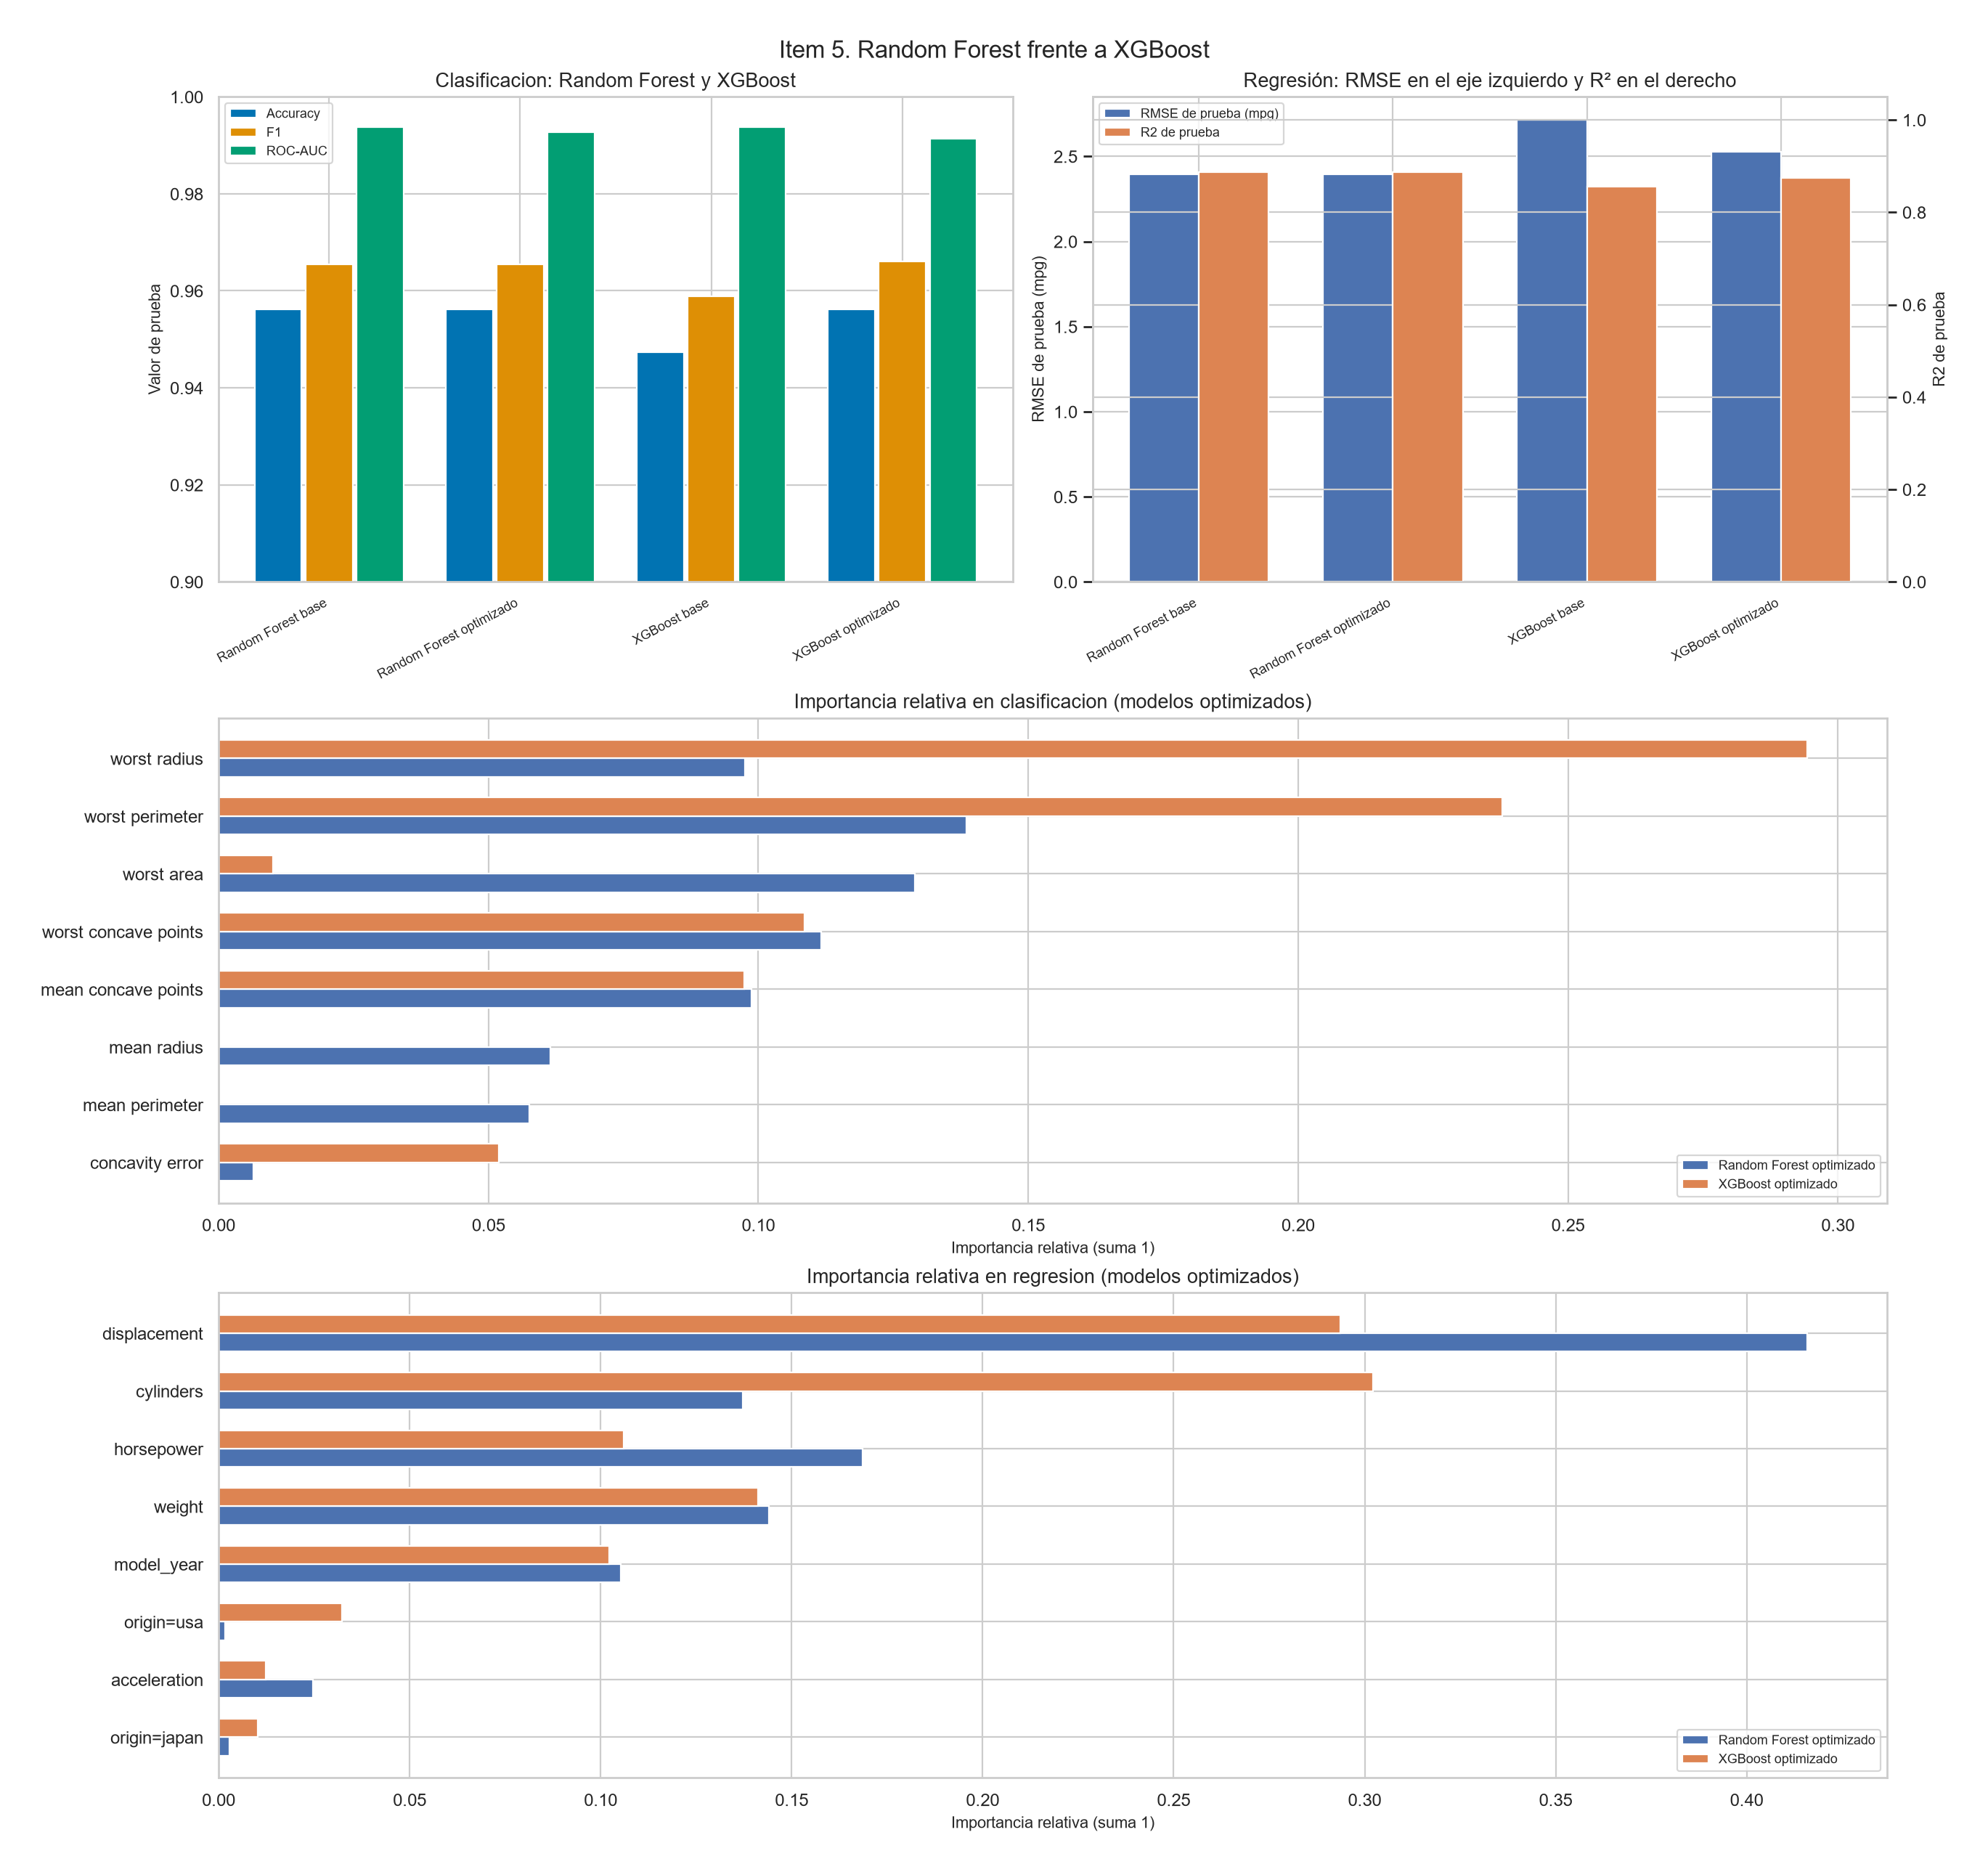

In [6]:
print('Pregunta 5. Clasificación en cáncer de mama')
show_models(results['item5']['classification']['models'])
print('Pregunta 5. Regresión en auto_mpg')
show_models(results['item5']['regression']['models'])
display(Image(filename='plots/item5_rf_vs_xgboost.png'))


## Conclusiones

| Pregunta | Ganador | Métrica principal | Valor | Conclusión |
| --- | --- | --- | --- | --- |
| Pregunta 1 | Regresión logística | ROC-AUC de prueba | 0.9954 | Gini y entropía se comparan entre sí y contra la regresión logística L2. |
| Pregunta 2 | Árbol error absoluto | RMSE de prueba (mpg) | 2.6448 | El árbol sin restricciones muestra la brecha de sobreajuste; el ganador es el menor RMSE de prueba. |
| Pregunta 3 | Regresión logística | ROC-AUC de prueba | 0.9954 | El ensamble se juzga contra el árbol y contra el mejor modelo individual. |
| Pregunta 4, clasificación | Bagging (200) | Accuracy de prueba del mejor bagging | 0.9474 | Bootstrap y promedio de árboles profundos frente a un solo árbol. |
| Pregunta 4, regresión | Bagging (200) | RMSE de prueba del mejor bagging | 2.3911 | La misma comparación en millas por galón, con OOB R². |
| Pregunta 5, clasificación | Random Forest base | ROC-AUC de prueba | 0.9937 | Bosque paralelo con submuestreo de variables frente a boosting de segundo orden. |
| Pregunta 5, regresión | Random Forest optimizado | RMSE de prueba (mpg) | 2.3960 | La misma comparación sobre auto_mpg, en versión base y optimizada. |

El patrón que se repite es el siguiente. Un árbol CART sin restricciones ajusta el entrenamiento hasta dejar poca o ninguna impureza y esa exactitud no se traslada completa a la prueba. La regresión regularizada, la poda, el bagging y el boosting atacan esa varianza por caminos distintos: penalización del coeficiente, eliminación de ramas, promedio de muestras bootstrap y corrección secuencial del residuo. En cáncer de mama la señal es fuerte y varios modelos superan 0.95 de ROC-AUC; la diferencia útil está en los centésimas y en el recall de la clase maligna. En auto_mpg la señal tiene una parte lineal grande (peso, potencia, cilindrada y año) y una parte de interacción que solo aparece cuando el árbol o el ensamble están regularizados. Los ganadores declarados con la métrica de prueba son: pregunta 1, Regresión logística; pregunta 2, Árbol error absoluto; pregunta 3, Regresión logística; pregunta 4, Bagging (200) en clasificación y Bagging (200) en regresión; pregunta 5, Random Forest base en clasificación y Random Forest optimizado en regresión.

### Limitaciones

- Hay un solo conjunto de prueba. La validación cruzada reduce la dependencia de una partición, pero cinco pliegues dan una prueba t de baja potencia.
- La validación cruzada de los modelos sintonizados reutiliza los pliegues de la búsqueda, así que esa media puede ser optimista. La prueba no entra en la búsqueda.
- El conjunto de prueba de cáncer de mama tiene 114 casos y el de auto_mpg tiene 79. Un cambio de unos pocos casos mueve la tercera cifra decimal.
- Las importancias de Random Forest y de XGBoost están normalizadas para la figura. Miden contribución al criterio de cada algoritmo, no efectos causales.
- La correlación entre miembros del ensamble se calcula con sus predicciones sobre la prueba. Es una diagnóstico del desacuerdo, no la correlación teórica entre muestras de entrenamiento.
- No hay una cohorte externa ni un coste distinto para los errores malignos. El recall maligno se reporta para que esa asimetría sea visible.

## Reproducibilidad

El README, el diseño experimental (`diseño_experimental.md`), las figuras, el JSON y `cuaderno_de_codigos.ipynb` salen de `src/run_experiments.py`. Volver a ejecutarlo regenera todos esos artefactos con la misma semilla.

```powershell

git clone https://github.com/paololuna-luw/cart-and-ensemble-benchmarks.git

cd cart-and-ensemble-benchmarks

python -m pip install -r requirements.txt

python src/run_experiments.py

```

El notebook ya está ejecutado. Para regenerar sus salidas:

```powershell

python -m ipykernel install --user --name tarea03py --display-name "Python 3.12 tarea03"

jupyter nbconvert --to notebook --execute cuaderno_de_codigos.ipynb --inplace --ExecutePreprocessor.kernel_name=tarea03py

```

Si existe `data/auto_mpg_clean.csv`, el script lo reutiliza para que la corrida no dependa de la red. Borrar ese archivo obliga a descargar de nuevo, primero por OpenML (`data_id=196`), después por seaborn y al final por el archivo de UCI.

Las tablas muestran cuatro decimales. `results_metrics.json` conserva el flotante completo de cada cálculo.


In [7]:
import run_experiments as exp
from sklearn.metrics import accuracy_score, r2_score
from sklearn.tree import DecisionTreeClassifier

breast = exp.load_breast_cancer_data()
x_train, x_test, y_train, y_test = exp.split_classification(breast['X'], breast['y'])
print('breast_cancer', breast['X'].shape, 'train', len(y_train), 'test', len(y_test))
tree = DecisionTreeClassifier(criterion='gini', random_state=exp.SEED)
tree.fit(x_train, y_train)
acc = float(accuracy_score(y_test, tree.predict(x_test)))
expected_acc = next(model['metrics']['accuracy_test'] for model in results['item1']['models'] if model['name'] == 'Gini')
print('accuracy Gini', acc, expected_acc)
if abs(acc - expected_acc) > 1e-12:
    raise AssertionError('El arbol Gini no reproduce el JSON')

mpg = exp.load_auto_mpg()
x_train, x_test, y_train, y_test = exp.split_regression(mpg['X'], mpg['y'])
print('auto_mpg', mpg['X'].shape, 'train', len(y_train), 'test', len(y_test))
shallow = exp.make_mpg_tree(max_depth=2)
shallow.fit(x_train, y_train)
score = float(r2_score(y_test, shallow.predict(x_test)))
expected_r2 = next(model['metrics']['r2_test'] for model in results['item2']['models'] if model['name'] == 'Árbol superficial')
print('R2 arbol superficial', score, expected_r2)
if abs(score - expected_r2) > 1e-10:
    raise AssertionError('El arbol superficial no reproduce el JSON')
print('Los dos ajustes de control coinciden con el JSON.')


breast_cancer (569, 30) train 455 test 114
accuracy Gini 0.9122807017543859 0.9122807017543859
[16:06:50] auto_mpg: usando cache local data/auto_mpg_clean.csv


auto_mpg (392, 7) train 313 test 79
R2 arbol superficial 0.5833631999053324 0.5833631999053324
Los dos ajustes de control coinciden con el JSON.


In [8]:
def walk(obj):
    if isinstance(obj, float):
        if not math.isfinite(obj):
            raise AssertionError('metrica no finita')
    elif isinstance(obj, dict):
        for value in obj.values():
            walk(value)
    elif isinstance(obj, list):
        for value in obj:
            walk(value)

walk(results)
readme = Path('README.md').read_text(encoding='utf-8')
import re
if re.search(r'\bNone\b', readme) or re.search(r'\bNaN\b|\bnan\b', readme):
    raise AssertionError('README con marcador vacio')
for figure in ['plots/item1_breast_cancer.png', 'plots/item2_auto_mpg.png', 'plots/item3_ensemble_clf.png', 'plots/item4_bagging.png', 'plots/item5_rf_vs_xgboost.png']:
    if not Path(figure).exists():
        raise AssertionError(figure)
print('JSON finito, README limpio y cinco figuras presentes.')
print('Respuestas en el README:', readme.count('### Respuesta Fundamentada: ¿Cuál es mejor?'))


JSON finito, README limpio y cinco figuras presentes.
Respuestas en el README: 5
